## Network dynamics analysis of networks trained on fixed probability offset task

In [2]:
%load_ext autoreload
%autoreload 2

import os
os.environ["JAX_PLATFORM_NAME"] = "cpu"
import sys
module_path = os.path.abspath(os.path.join('../..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from pathlib import Path
import jax
import jax.numpy as jnp
from flax.training import checkpoints
from flax import serialization
from agents.a2c_rnn_flax import A2CRNNFlax, init_network_and_params
from environments.components.train_state import create_train_state
from environments.treadmill_env_jax import treadmill_session_default_params
import matplotlib.pyplot as plt
from nb_analysis_tools import load_trajectory_data, parse_behavioral_data
from aux_funcs import format_plot, format_pc_plot
import numpy as np
from sklearn.decomposition import PCA
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d.art3d import Line3DCollection
import seaborn as sns
from copy import copy
from nb_dynamics_plotting import *

plt.rcParams['font.family'] = 'Helvetica Light'

In [3]:
REWARD_RATE_THRESHOLD = 0.065

FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS = [
    '../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl',
    '../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl',
    '../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl',
    '../../../results/fixed_exp_gru_initial_prob_offset_v4_net3/trajectories_20260529_160251.pkl',
    '../../../results/fixed_exp_gru_initial_prob_offset_v4_net4/trajectories_20260529_163734.pkl',]

FIXED_EXP_GRU_INITIAL_PROB_OFFSET_CHECKPOINTS = [
    '../../../checkpoints/fixed_exp_gru_initial_prob_offset_v4_net0/checkpoint_0',
    '../../../checkpoints/fixed_exp_gru_initial_prob_offset_v4_net1/checkpoint_0',
    '../../../checkpoints/fixed_exp_gru_initial_prob_offset_v4_net2/checkpoint_0',
    '../../../checkpoints/fixed_exp_gru_initial_prob_offset_v4_net3/checkpoint_0',
    '../../../checkpoints/fixed_exp_gru_initial_prob_offset_v4_net4/checkpoint_0',
    ]

In [4]:
HIDDEN_SIZE = 64
ACTION_SIZE = 2
OBS_SIZE = 4
RNN_TYPE = "GRU"
UNIT_NOISE_STD = 1e-2
LEARNING_RATE = 0
SEED = 0
NUM_ENVS = 1

# Configuration
CONFIG = {
    'hidden_size': 64,
    'action_size': 2,
    'obs_size': 4,
    'rnn_type': 'GRU',  # or 'VANILLA'
    'unit_noise_std': 0.0,
}

# Define input context
# Input format: [obs(4), prev_action_onehot(2), prev_reward(1)]
input_dim = CONFIG['obs_size'] + CONFIG['action_size'] + 1

In [5]:
# --- INITIALIZE NETWORK + TRAIN STATE ---
rng_key = jax.random.key(SEED)
net_init_key, rng_key = jax.random.split(rng_key)

network, params = init_network_and_params(
    hidden_size=HIDDEN_SIZE,
    action_size=ACTION_SIZE,
    obs_size=OBS_SIZE,
    rnn_type=RNN_TYPE,
    unit_noise_std=UNIT_NOISE_STD,
    rng_key=net_init_key,
)

train_state = create_train_state(
    rng_key=rng_key,
    obs_size=OBS_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_envs=NUM_ENVS,
    learning_rate=LEARNING_RATE,
    params=params,
)

Networks passing threshold 0.065: [0, 1, 2, 3, 4]
Mean reward rates: [0.06727666 0.06663333 0.06722999 0.06624    0.06619667]


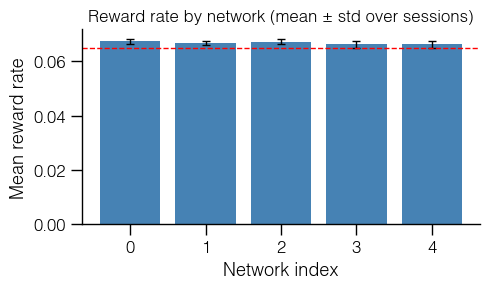

In [5]:
reward_rates = []

for net_idx, dir_path in enumerate(FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS):
    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]
    session_means = traj_data['reward'].reshape(15, -1).mean(axis=1)
    reward_rates.append(session_means)

means = np.array([s.mean() for s in reward_rates])
stds  = np.array([s.std()  for s in reward_rates])

passing_indices     = [i for i, m in enumerate(means) if m >= REWARD_RATE_THRESHOLD]
PASSING_NETWORKS    = [FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS[i]    for i in passing_indices]
PASSING_CHECKPOINTS = [FIXED_EXP_GRU_INITIAL_PROB_OFFSET_CHECKPOINTS[i] for i in passing_indices]
print(f'Networks passing threshold {REWARD_RATE_THRESHOLD}: {passing_indices}')
print(f'Mean reward rates: {means}')

x = np.arange(len(means))
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(x, means, yerr=stds, color='steelblue', edgecolor='none',
       error_kw=dict(lw=1, capsize=3, capthick=1))
ax.axhline(REWARD_RATE_THRESHOLD, color='red', linewidth=1, linestyle='--', label='threshold')
ax.set_xticks(x)
ax.set_xticklabels([f'{i}' for i in x])
ax.set_ylabel('Mean reward rate')
ax.set_xlabel('Network index')
ax.set_title('Reward rate by network (mean ± std over sessions)')
format_plot(ax)
plt.tight_layout()
plt.show()


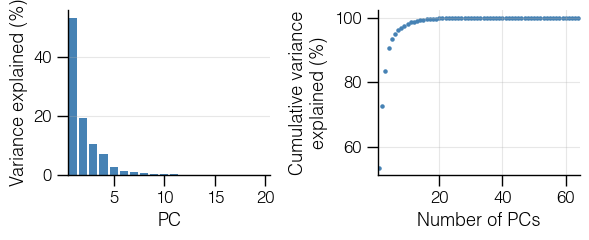

PCs to reach 90%: 4
PCs to reach 95%: 7


In [6]:
dir_path = PASSING_NETWORKS[0]

traj_data = {}

for env_idx in range(15):
    traj_data_raw = load_trajectory_data(dir_path)
    traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
    for key in traj_data_env.keys():
        if key in traj_data:
            traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
        else:
            traj_data[key] = traj_data_env[key]
    
pca = PCA()
pca.fit(traj_data['actor_hidden'])
pc_activities = pca.transform(traj_data['actor_hidden'])

fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))

evr  = pca.explained_variance_ratio_
cumr = np.cumsum(evr)
pcs  = np.arange(1, len(evr) + 1)

axes[0].bar(pcs, evr * 100, color='steelblue', width=0.8)
axes[0].set_xlabel('PC')
axes[0].set_ylabel('Variance explained (%)')
axes[0].set_xlim(0.5, min(20, len(evr)) + 0.5)
axes[0].grid(True, axis='y', alpha=0.3)

axes[1].scatter(pcs, cumr * 100, marker='o', s=5, color='steelblue')
axes[1].set_xlabel('Number of PCs')
axes[1].set_ylabel('Cumulative variance\nexplained (%)')
axes[1].set_xlim(0.5, len(evr) + 0.5)
axes[1].grid(True, alpha=0.3)

format_plot(axes)

plt.tight_layout()
plt.show()

print(f'PCs to reach 90%: {np.searchsorted(cumr, 0.90) + 1}')
print(f'PCs to reach 95%: {np.searchsorted(cumr, 0.95) + 1}')

### Plot single patch dynamics for each patch type
Hidden state trajectories are cylindrical spirals when projected into 3D. These trajectories rapidly circularly oscillate, but also follow a slower time course along a third dimension.

In [7]:
for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx}: {dir_path} ===')

    if net_idx != 1:
        continue

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===
=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===


=== Network 2: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl ===
=== Network 3: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net3/trajectories_20260529_160251.pkl ===
=== Network 4: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net4/trajectories_20260529_163734.pkl ===


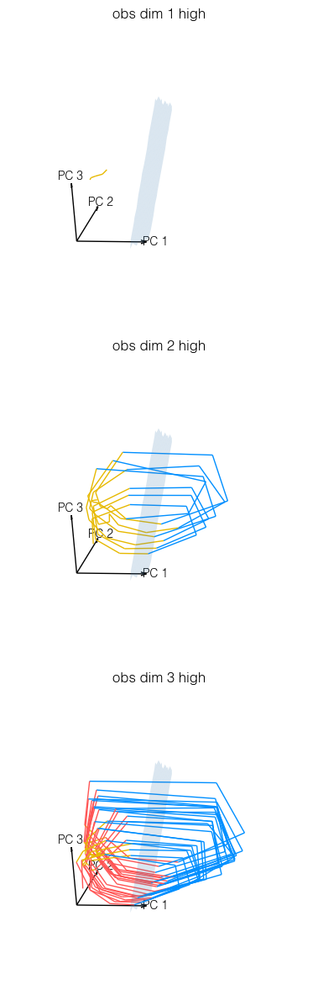

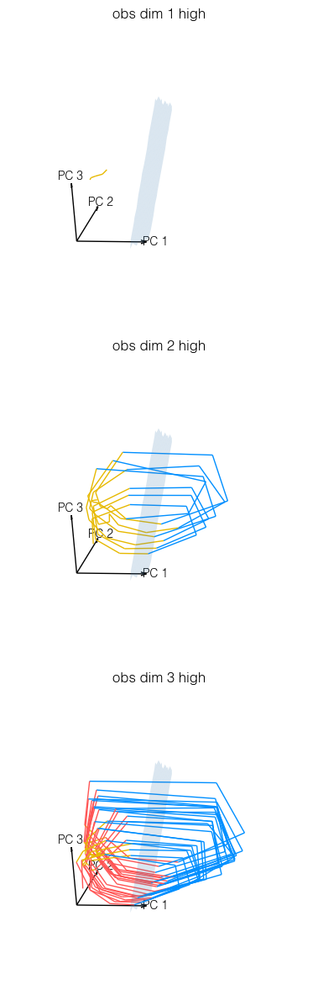

In [8]:
plot_patch_trajectories_3d(
    traj_data,
    max_trajectories=1,
    params=net_params,
    pca=pca,
    rz=80, rx=20, ry=0,
    input_color_map=[
        (np.array([1, 0, 0, 1, 0, 1, 0]), '#ff5555'),
        (np.array([1, 0, 0, 1, 1, 0, 0]), '#008fff'),
        (np.array([1, 0, 0, 1, 1, 0, 1]), '#008fff'),
        (np.array([1, 0, 0, 0, 0, 1, 0]), '#e7b900'),
    ]
)

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Light.
  fig.canvas.print_figure(bytes_io, **kw)


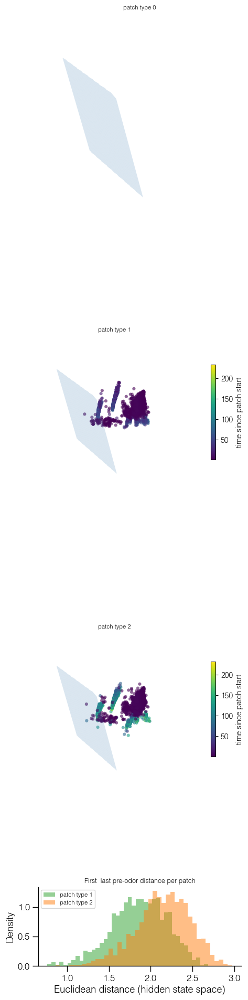

=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===


/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Light.
  fig.canvas.print_figure(bytes_io, **kw)


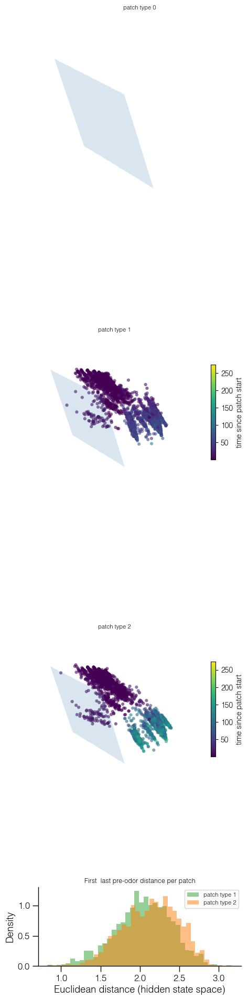

=== Network 2: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl ===


/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Light.
  fig.canvas.print_figure(bytes_io, **kw)


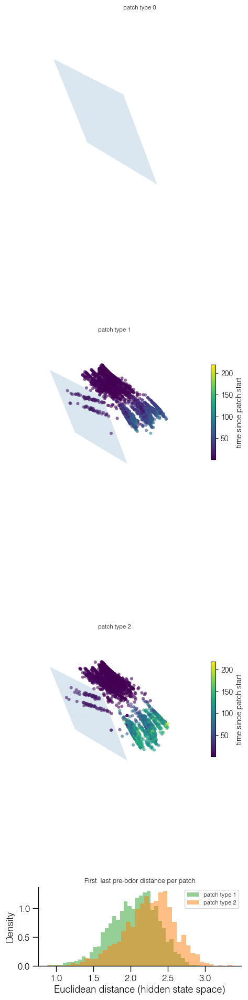

In [ ]:
for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    fig = plot_patch_endpoints_3d(traj_data, pca, params=net_params, azim=60, plot_starts=True, plot_ends=True)
    plt.show()

### Fixed points of trained networks
Trained networks show a few common features:
1. A single fixed point or cluster of fixed points when the visual cue is off.
1. The emergence of a line of marginally stable fixed points when the visual cue is turned on and the agent is running.


Network 0


Trial 0, patch 3  (global steps 447–564, length 118)  → 70 segments with ≥2 steps


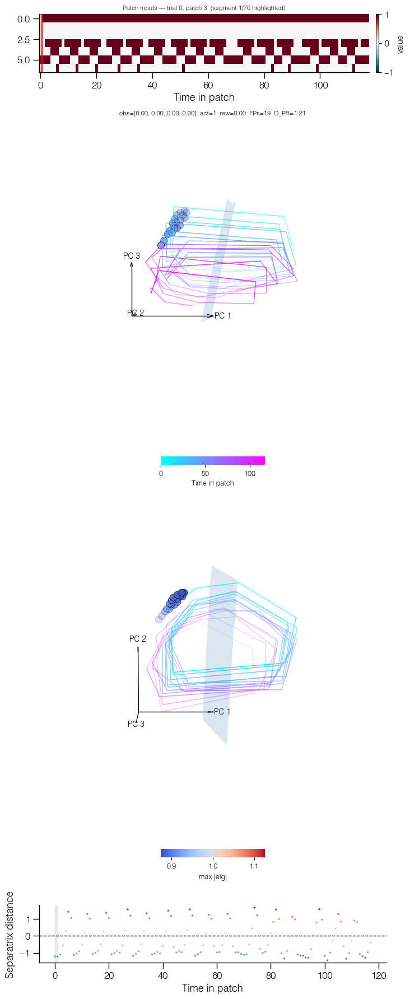

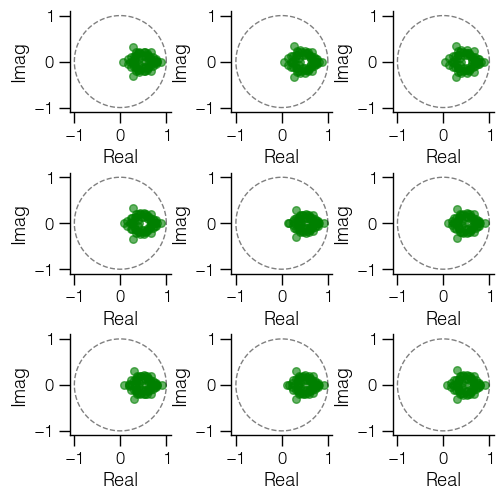

<Figure size 640x480 with 0 Axes>

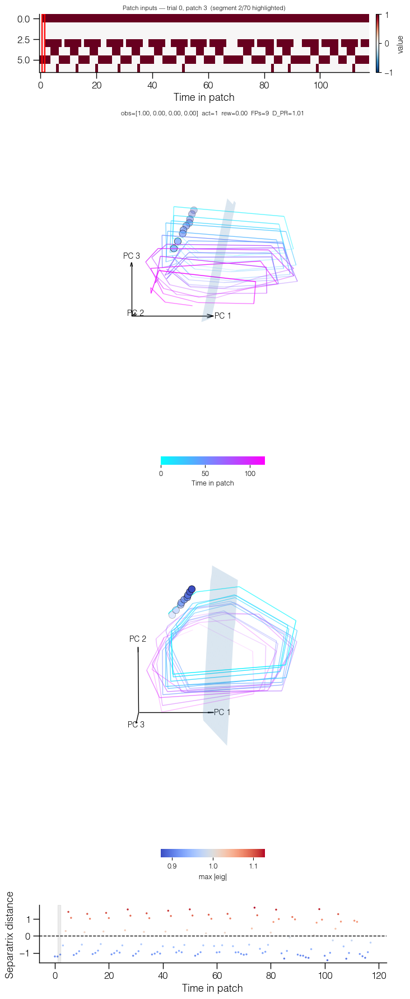

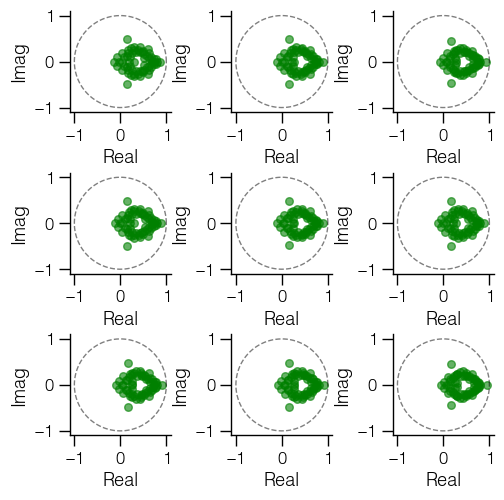

<Figure size 640x480 with 0 Axes>

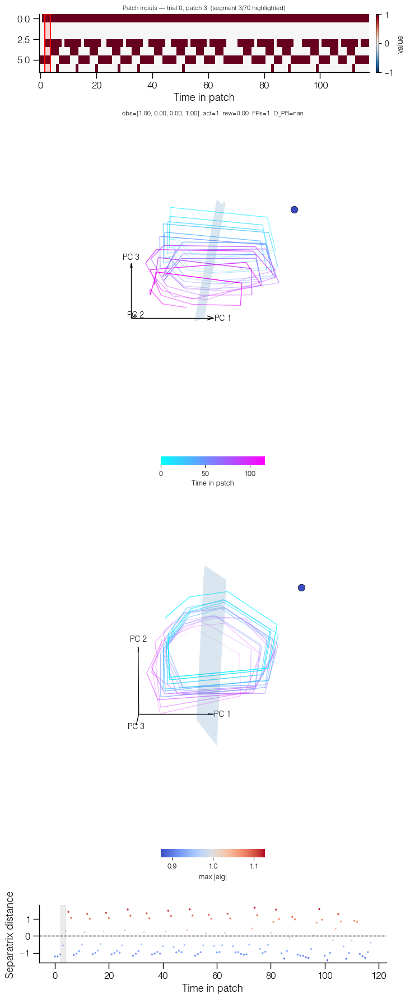

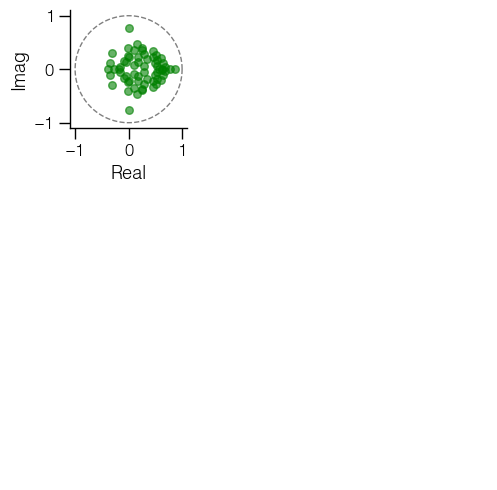

<Figure size 640x480 with 0 Axes>

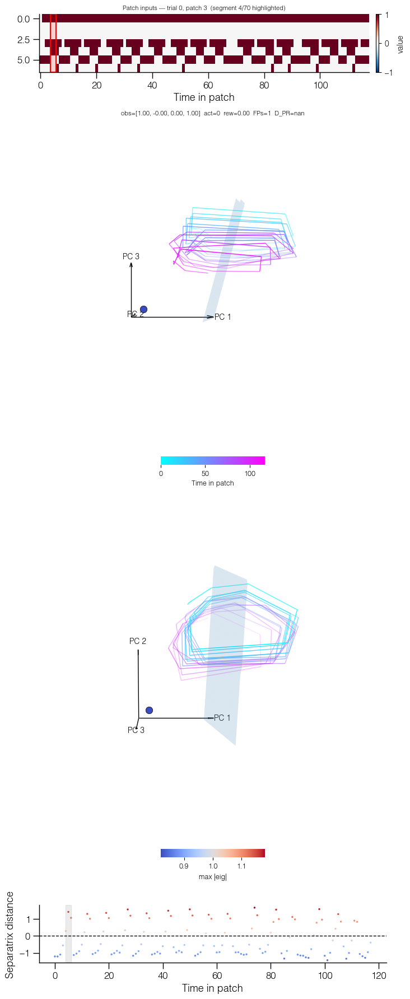

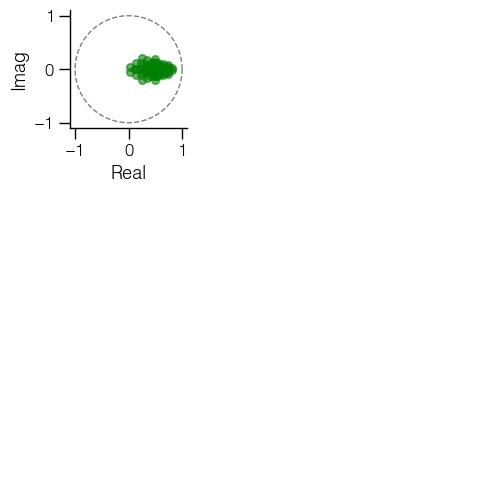

<Figure size 640x480 with 0 Axes>

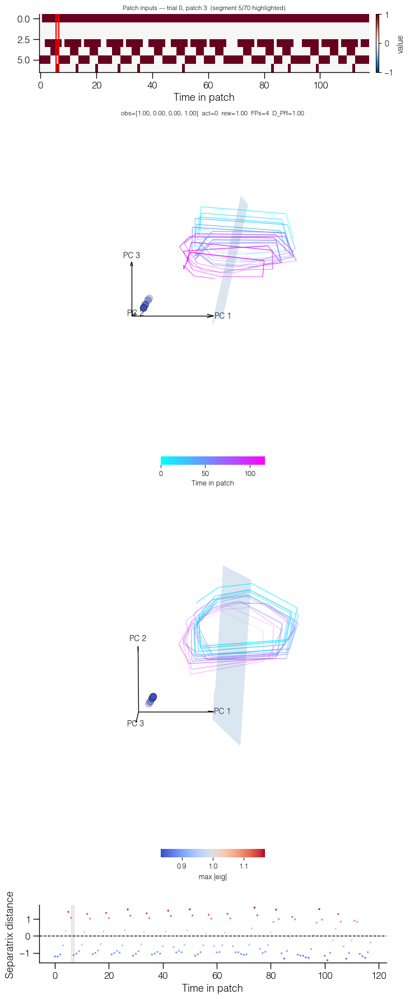

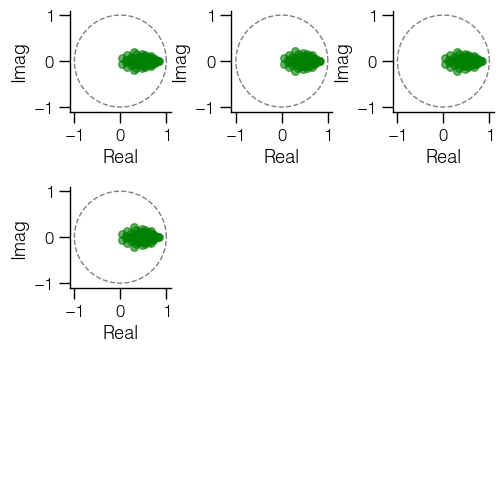

<Figure size 640x480 with 0 Axes>

Trial 0, patch 3  (global steps 447–564, length 118)  → 5 unique inputs


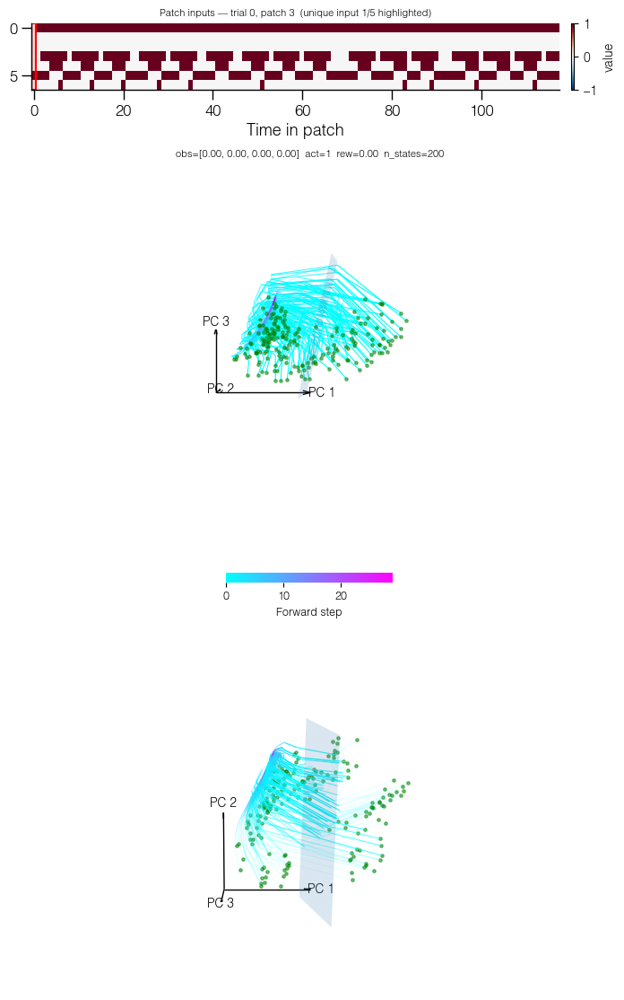

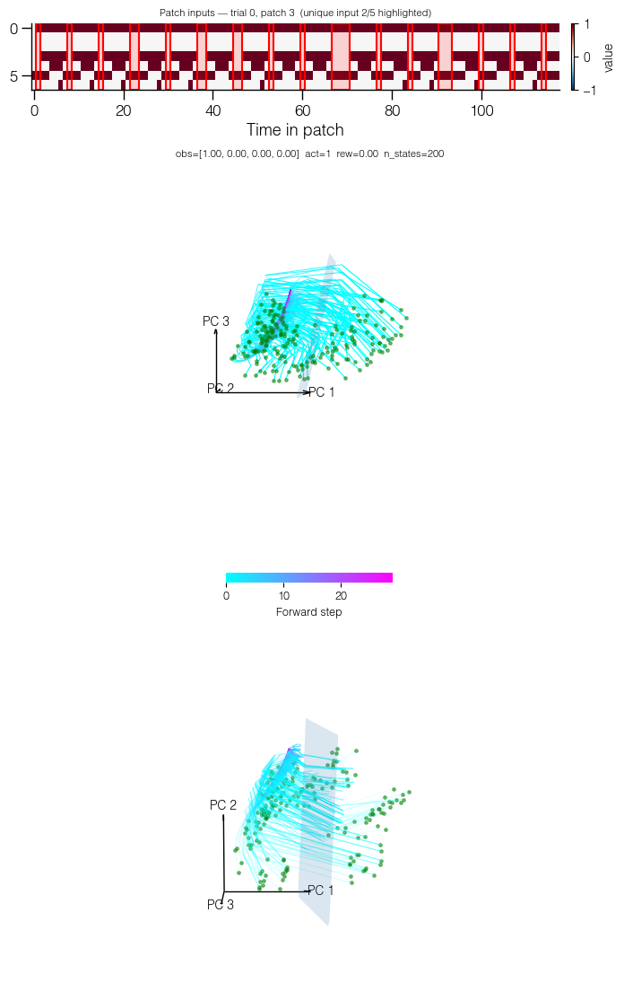

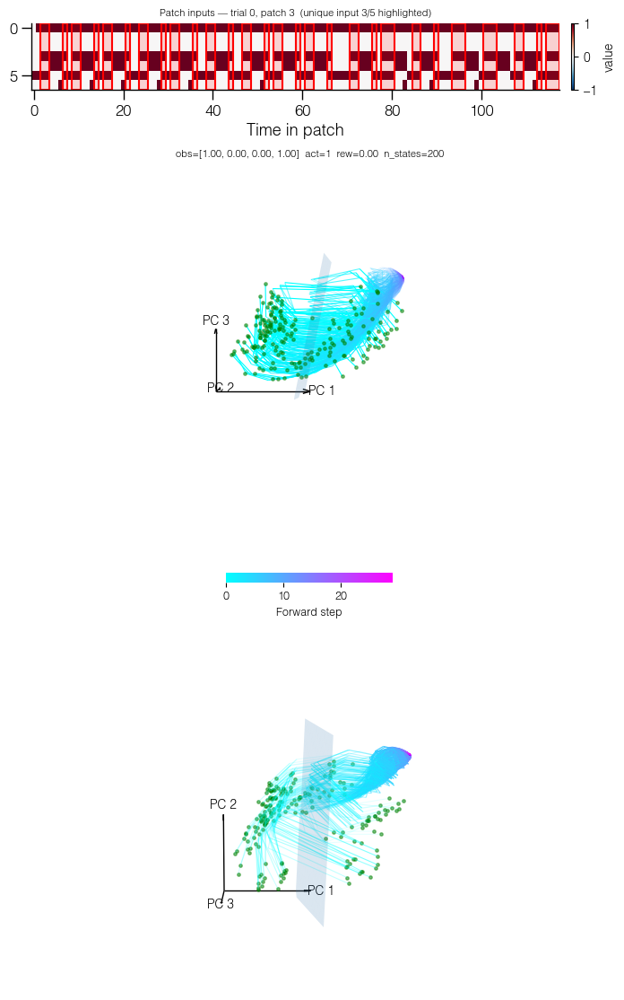

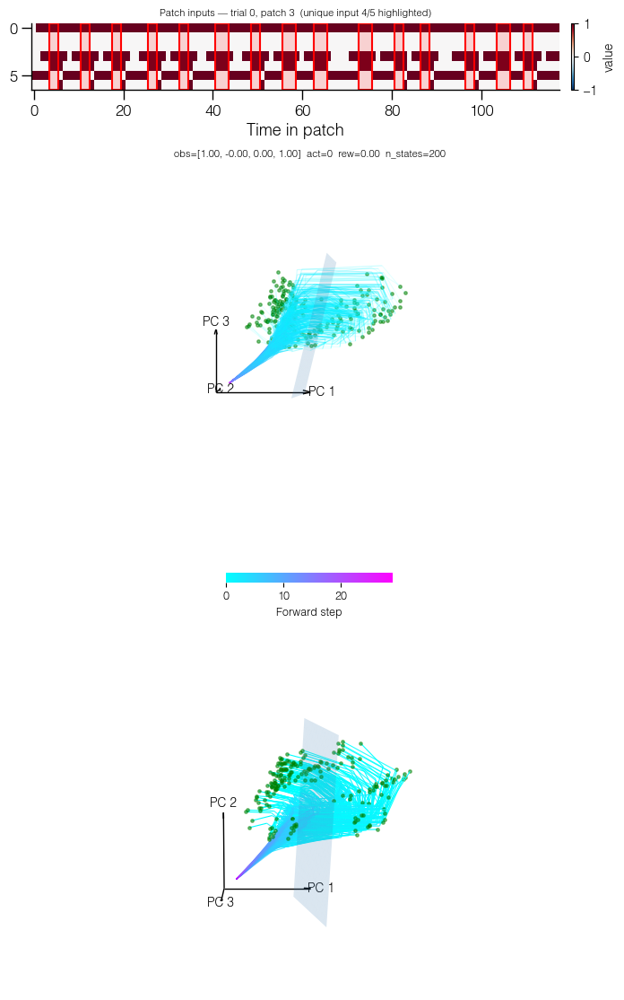

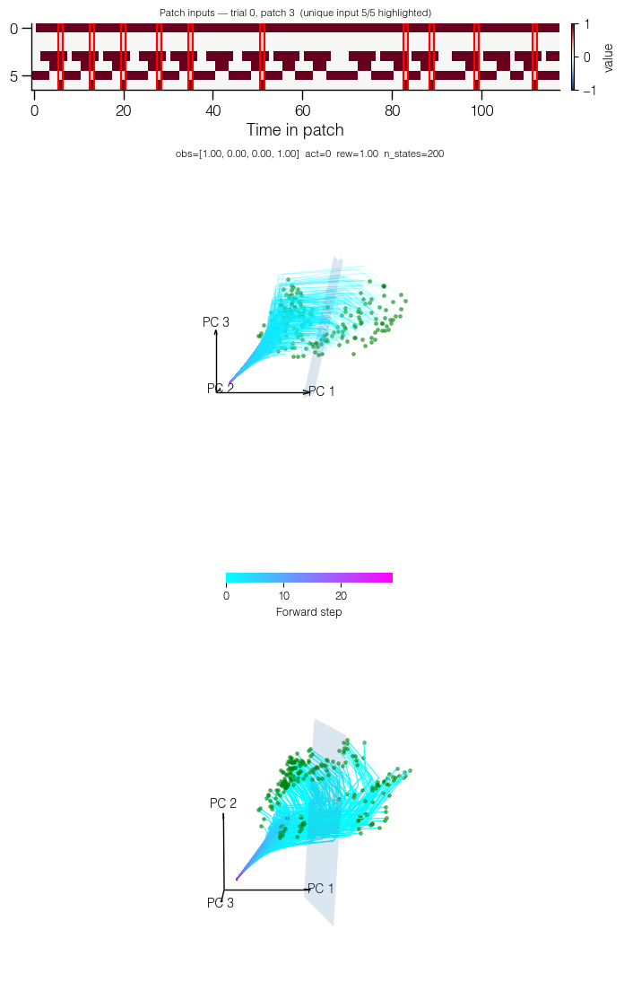

In [29]:
for net_idx, (traj_path, ckpt_path) in enumerate(
    zip(FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS, FIXED_EXP_GRU_INITIAL_PROB_OFFSET_CHECKPOINTS)
):
    if net_idx != 0:
        continue
    print(f'{"="*60}')
    print(f'Network {net_idx}')
    print(f'{"="*60}')

    # Load trajectory data and fit PCA
    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(traj_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    # Load checkpoint params for this network
    restored   = checkpoints.restore_checkpoint(
            ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = restored.params

    plot_patch_segments_with_fixed_points(
        traj_data, net_params, network, pca,
        trial_idx=0,
        patch_idx=3,
        patch_type=2,
        n_fp_attempts=300,
        fp_tol=5e-3,
        azim=270,
        elev=0,
        azim2=90 + 180,
        elev2=160 + -60,
        includes_actions_and_rewards=True,
        stop_after_unique_inputs=True,
        traj_cmap=sns.color_palette(palette='cool', as_cmap=True),
        save_dir=os.path.join('../../../figures', Path(traj_path).parent.name),
        plot_current_segment=False,
    )

    plot_patch_segments_forward_runs(
        traj_data, net_params, network, pca,
        trial_idx=0,
        patch_idx=3,
        patch_type=2,
        n_states=200,
        n_forward_steps=30,
        azim=270,
        elev=0,
        azim2=90 + 180,
        elev2=160 + -60,
        includes_actions_and_rewards=True,
        traj_cmap=sns.color_palette(palette='cool', as_cmap=True),
        save_dir=os.path.join('../../../figures', Path(traj_path).parent.name),
    )

### States immediately prior to odor onset
Within a patch but immediately prior to odor onset, states have graded accumulated reward representations. They also contain significant information about the duration of the inter site interval immediately prior to them. 

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


Patch 1: plotting 2000/8375 points (23.9%)
Patch 2: plotting 2000/24386 points (8.2%)
Patch 1: plotting 2000/8375 points (23.9%)
Patch 2: plotting 2000/24386 points (8.2%)
Patch 1: plotting 2000/8375 points (23.9%)
Patch 2: plotting 2000/24386 points (8.2%)


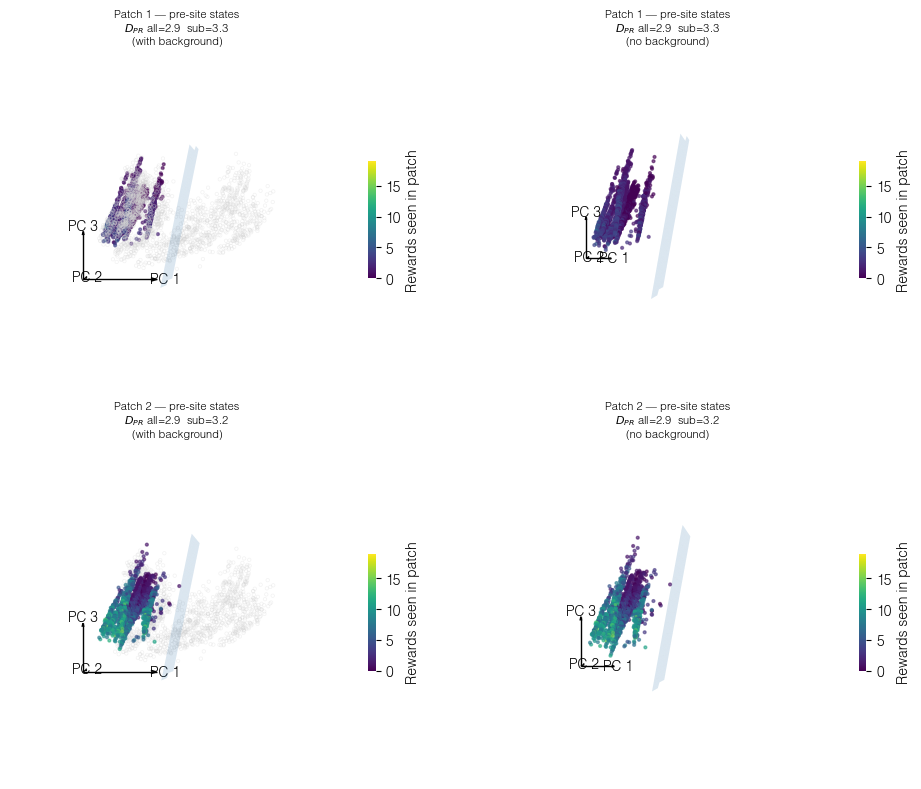

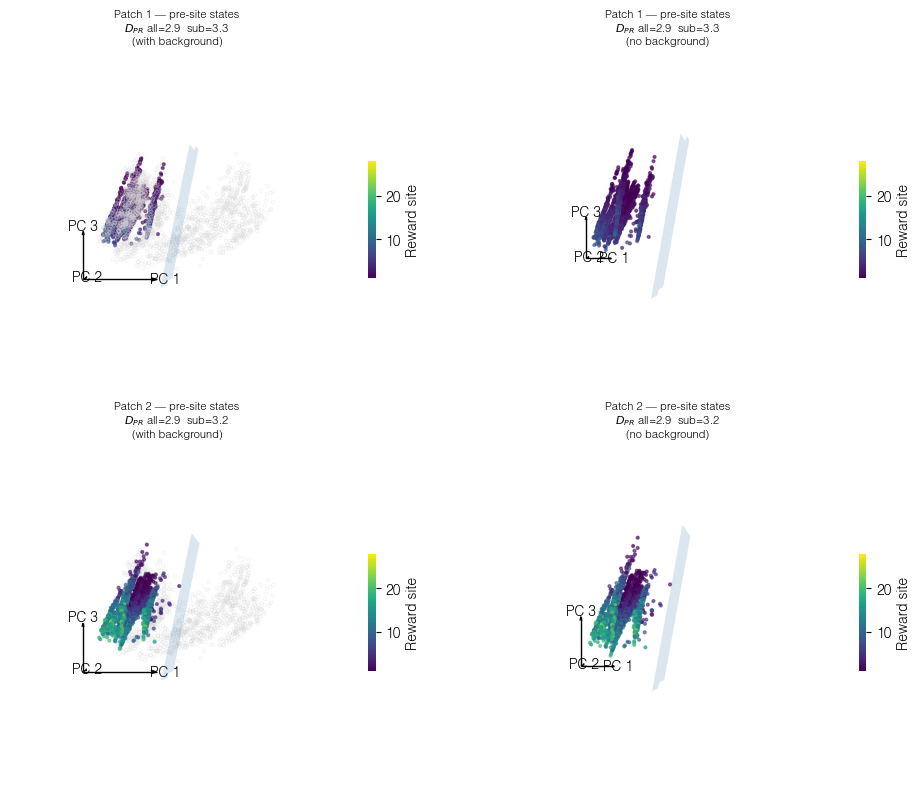

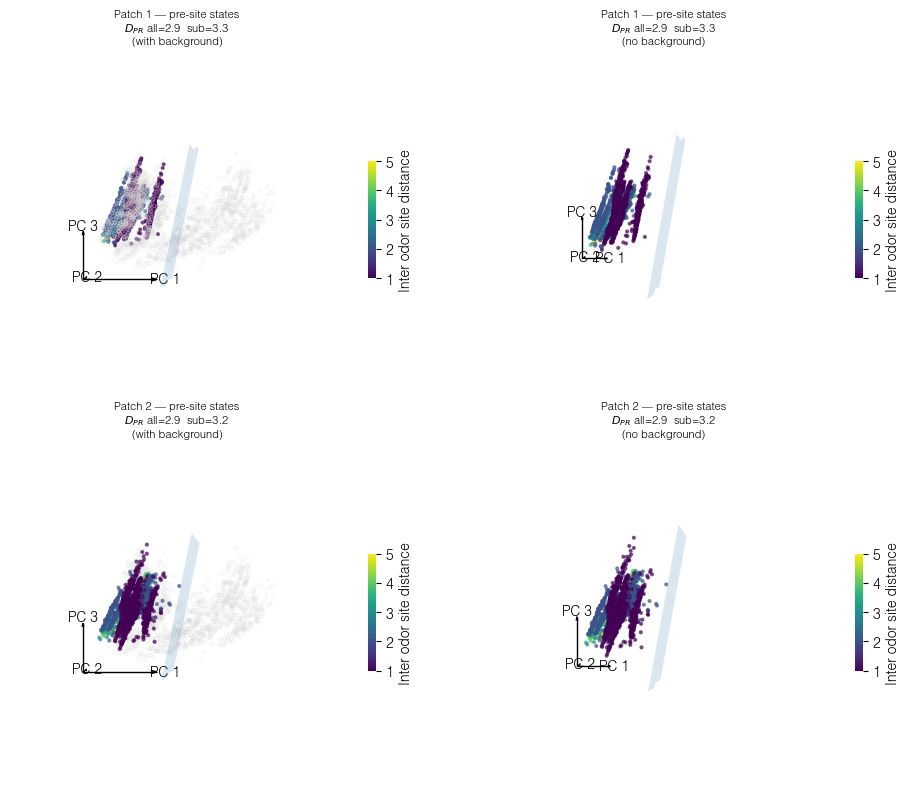

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===


Patch 1: plotting 2000/10183 points (19.6%)
Patch 2: plotting 2000/22596 points (8.9%)
Patch 1: plotting 2000/10183 points (19.6%)
Patch 2: plotting 2000/22596 points (8.9%)
Patch 1: plotting 2000/10183 points (19.6%)
Patch 2: plotting 2000/22596 points (8.9%)


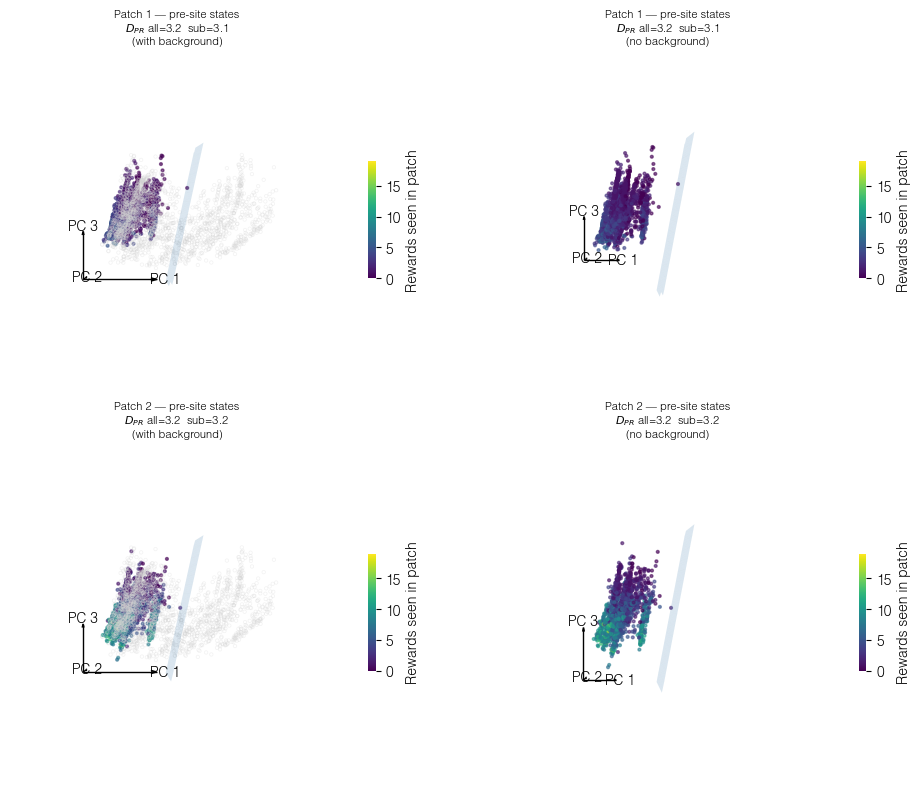

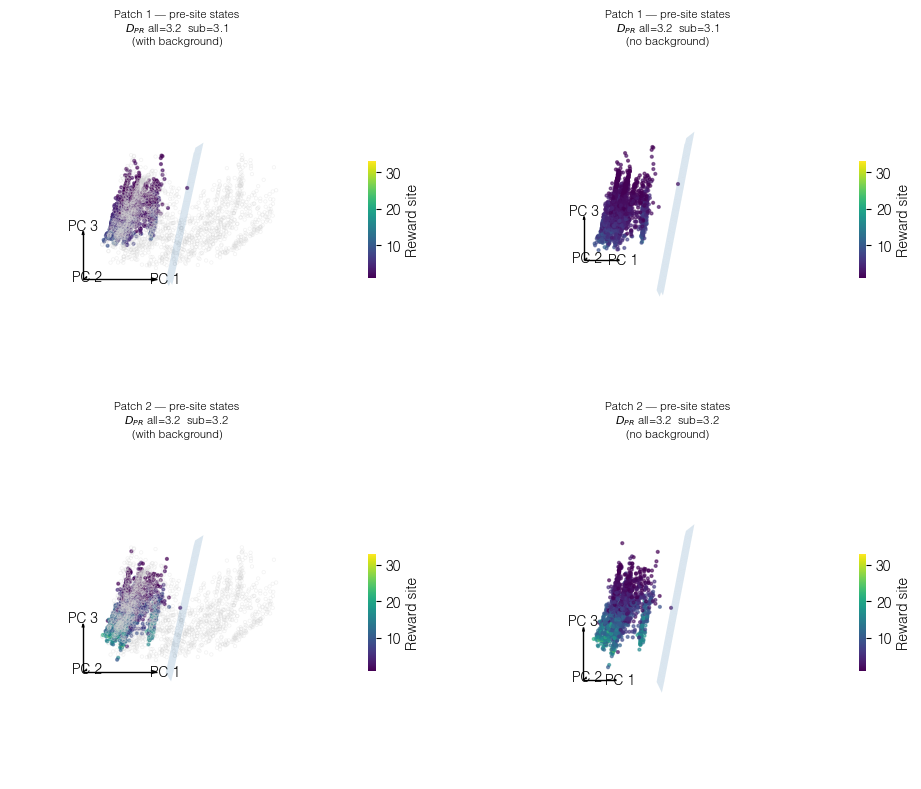

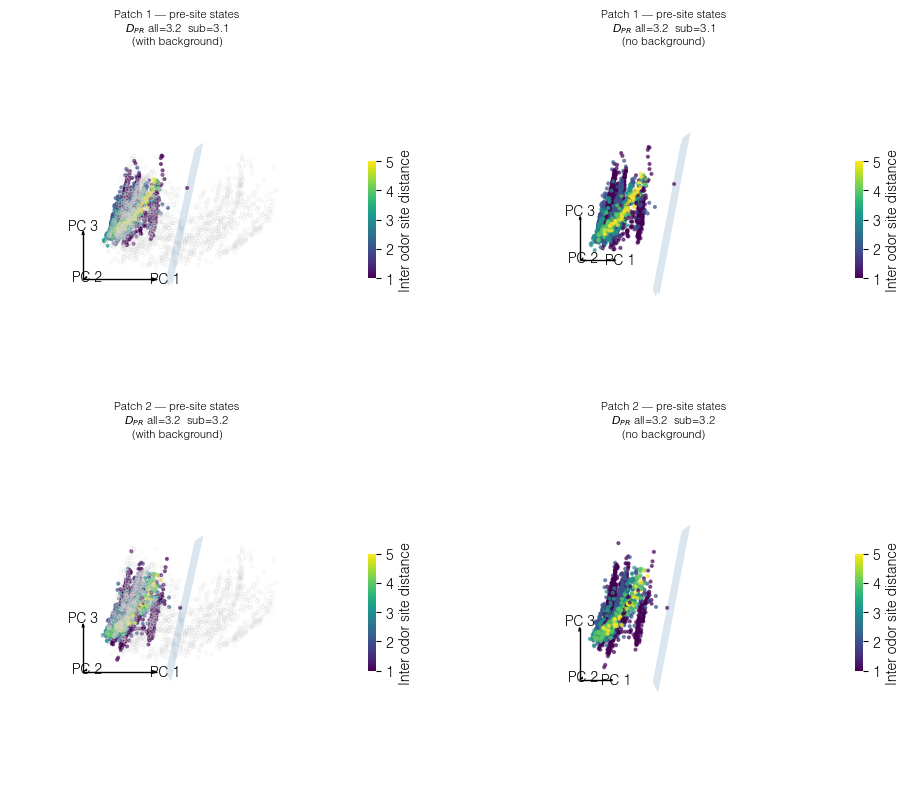

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

=== Network 2: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl ===


Patch 1: plotting 2000/9389 points (21.3%)
Patch 2: plotting 2000/23181 points (8.6%)
Patch 1: plotting 2000/9389 points (21.3%)
Patch 2: plotting 2000/23181 points (8.6%)
Patch 1: plotting 2000/9389 points (21.3%)
Patch 2: plotting 2000/23181 points (8.6%)


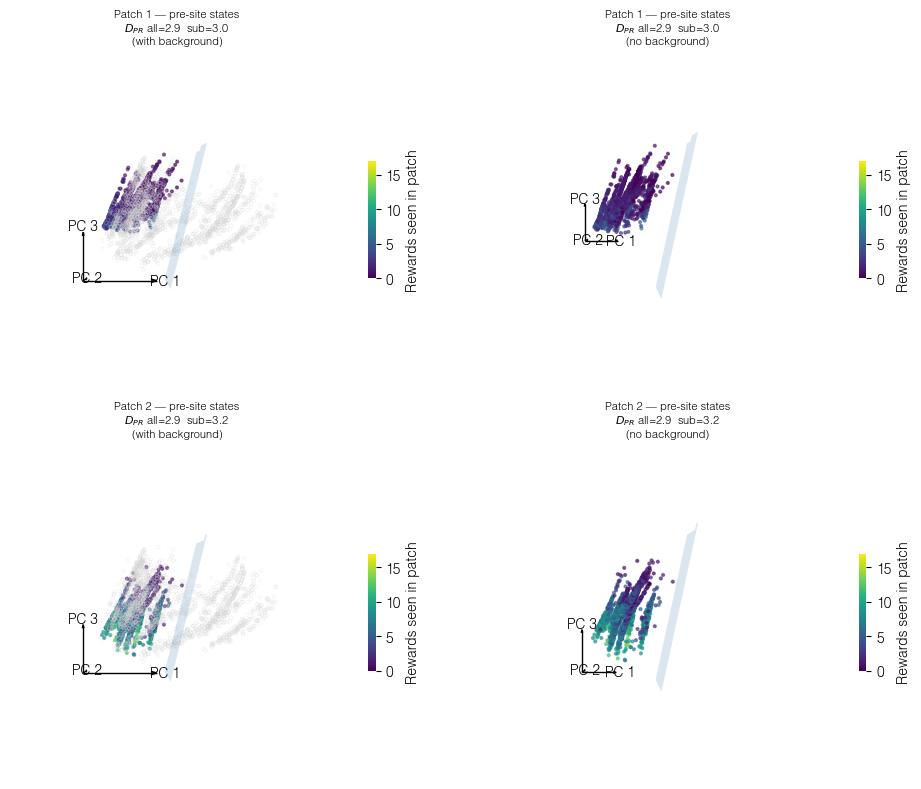

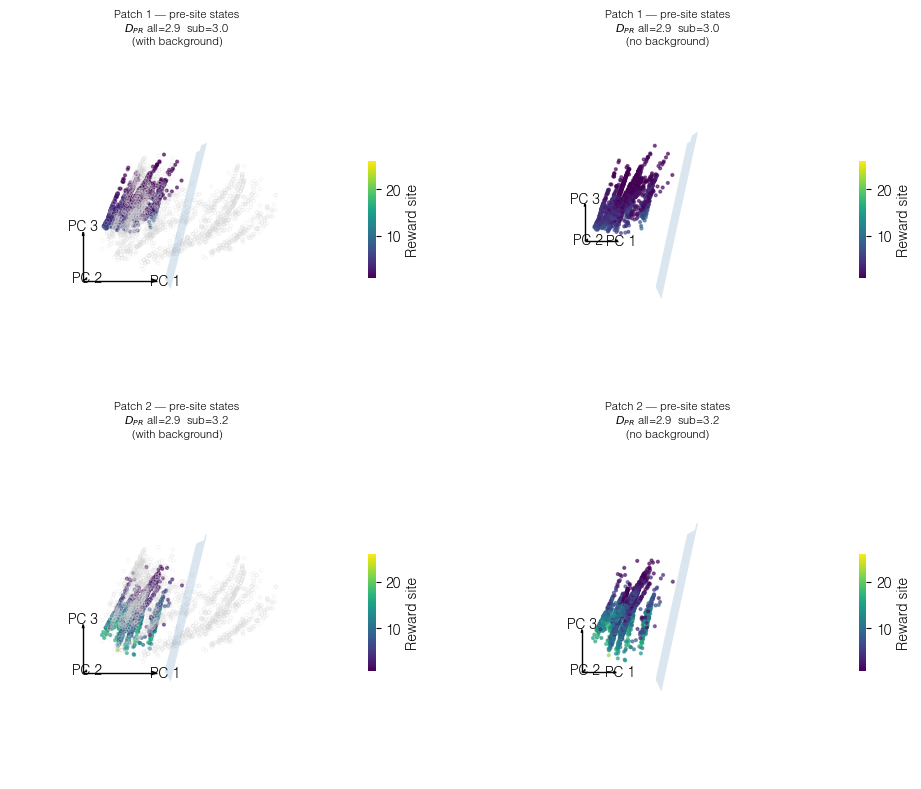

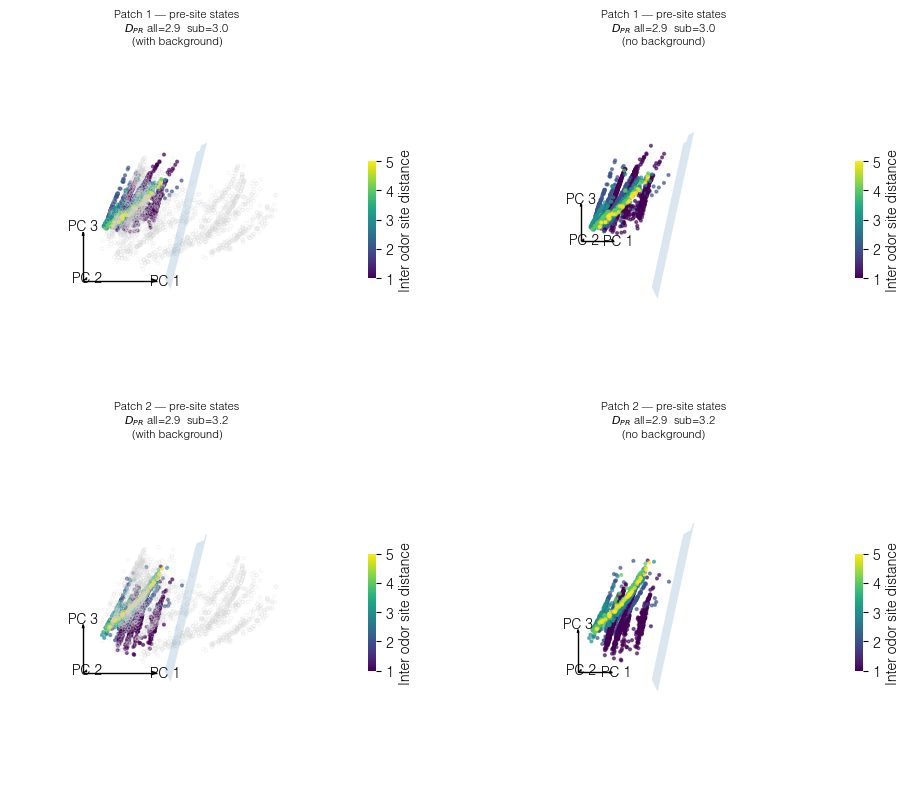

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

=== Network 3: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net3/trajectories_20260529_160251.pkl ===


Patch 1: plotting 2000/8352 points (23.9%)
Patch 2: plotting 2000/23077 points (8.7%)
Patch 1: plotting 2000/8352 points (23.9%)
Patch 2: plotting 2000/23077 points (8.7%)
Patch 1: plotting 2000/8352 points (23.9%)
Patch 2: plotting 2000/23077 points (8.7%)


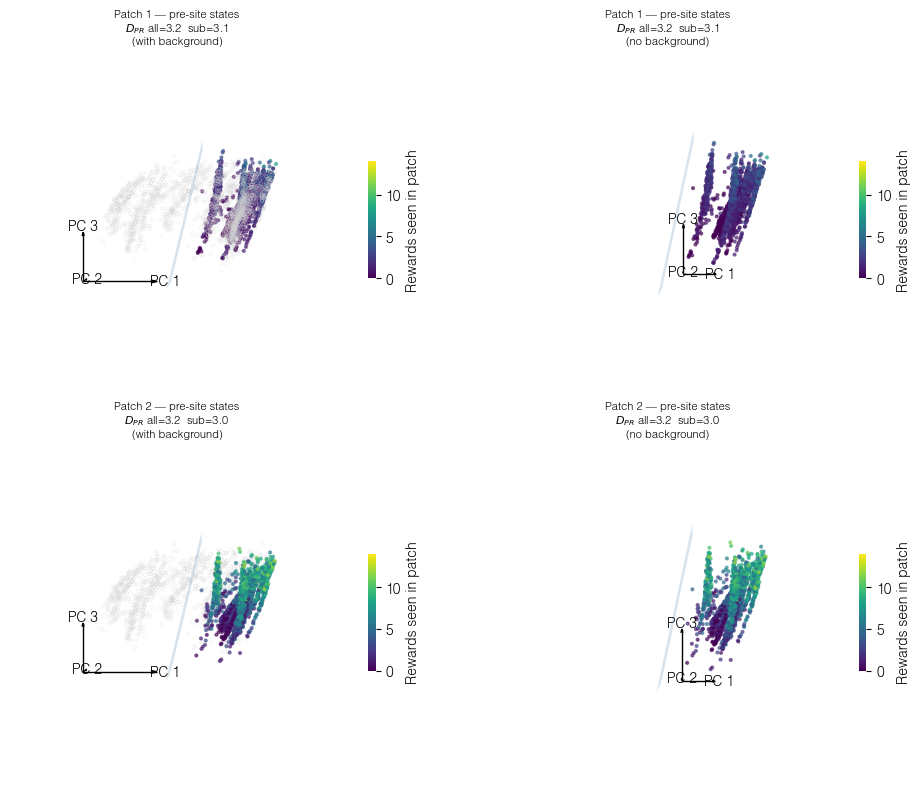

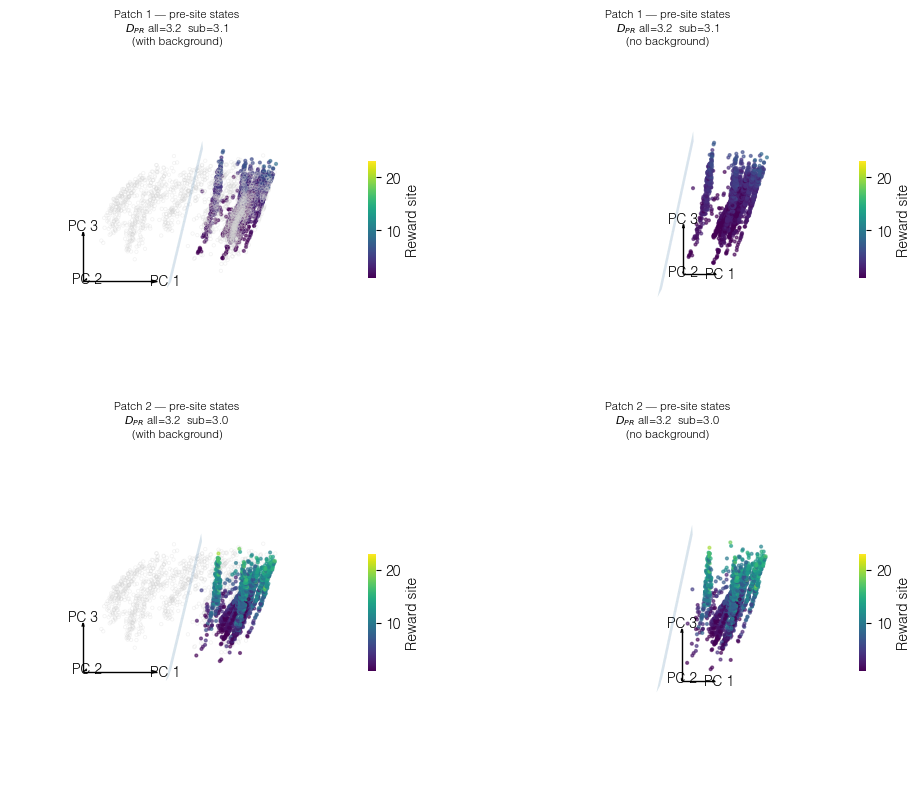

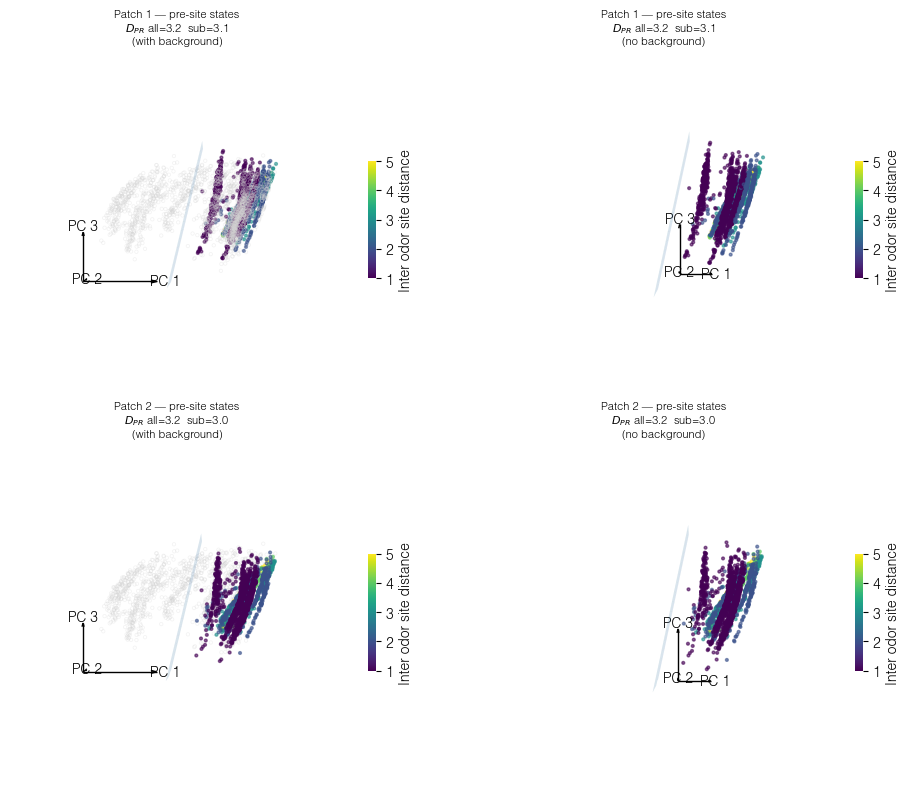

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

=== Network 4: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net4/trajectories_20260529_163734.pkl ===


Patch 1: plotting 2000/8868 points (22.6%)
Patch 2: plotting 2000/24434 points (8.2%)
Patch 1: plotting 2000/8868 points (22.6%)
Patch 2: plotting 2000/24434 points (8.2%)
Patch 1: plotting 2000/8868 points (22.6%)
Patch 2: plotting 2000/24434 points (8.2%)


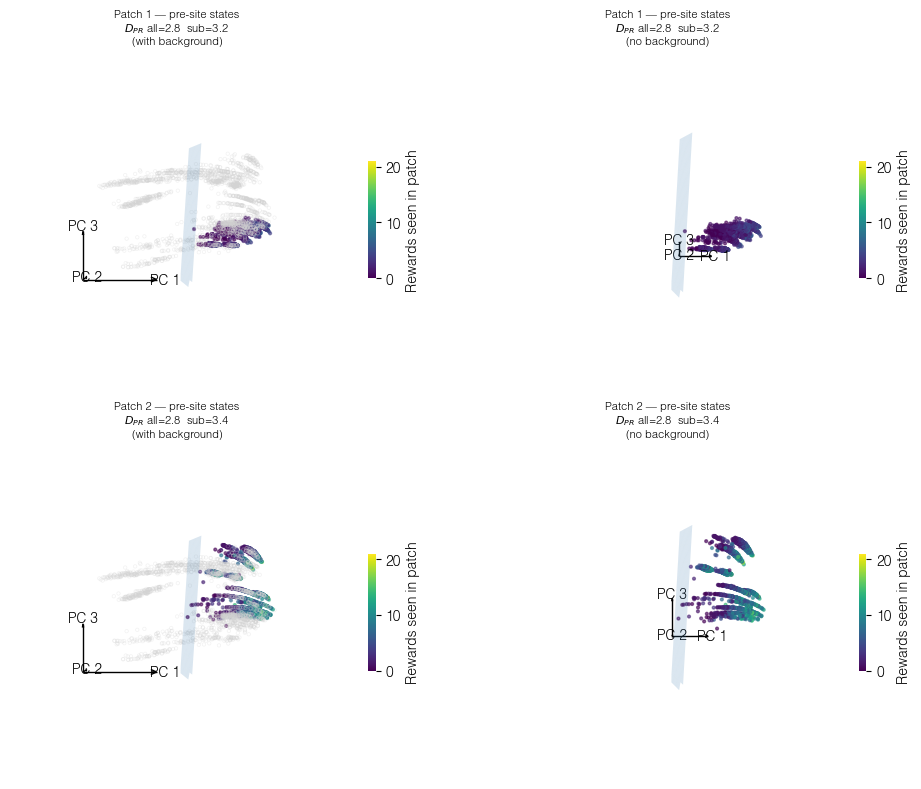

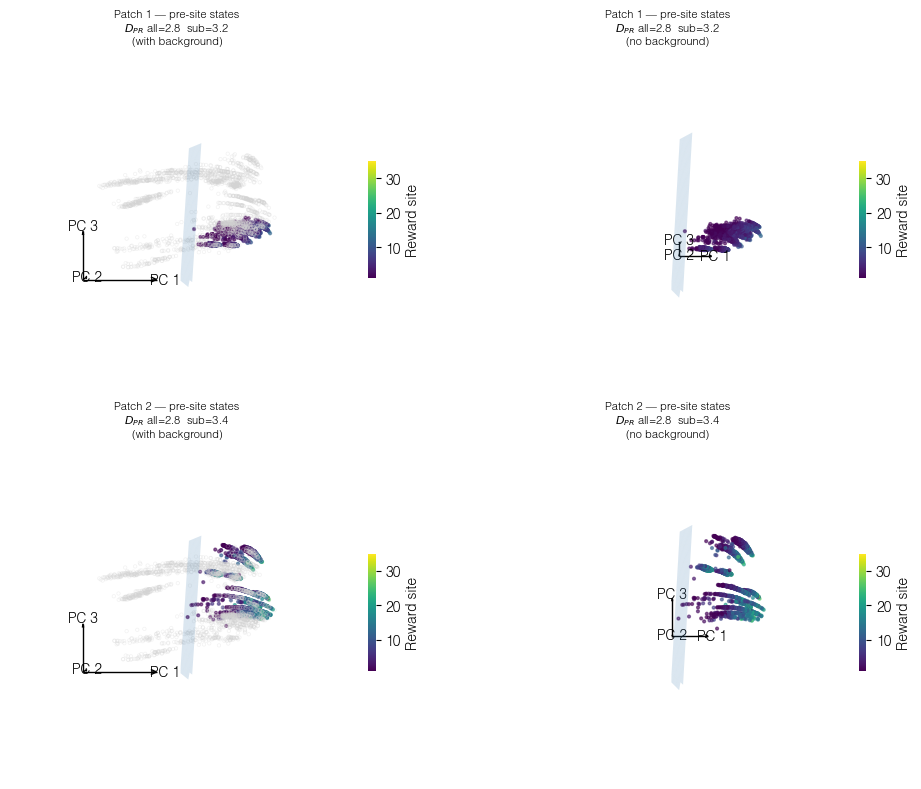

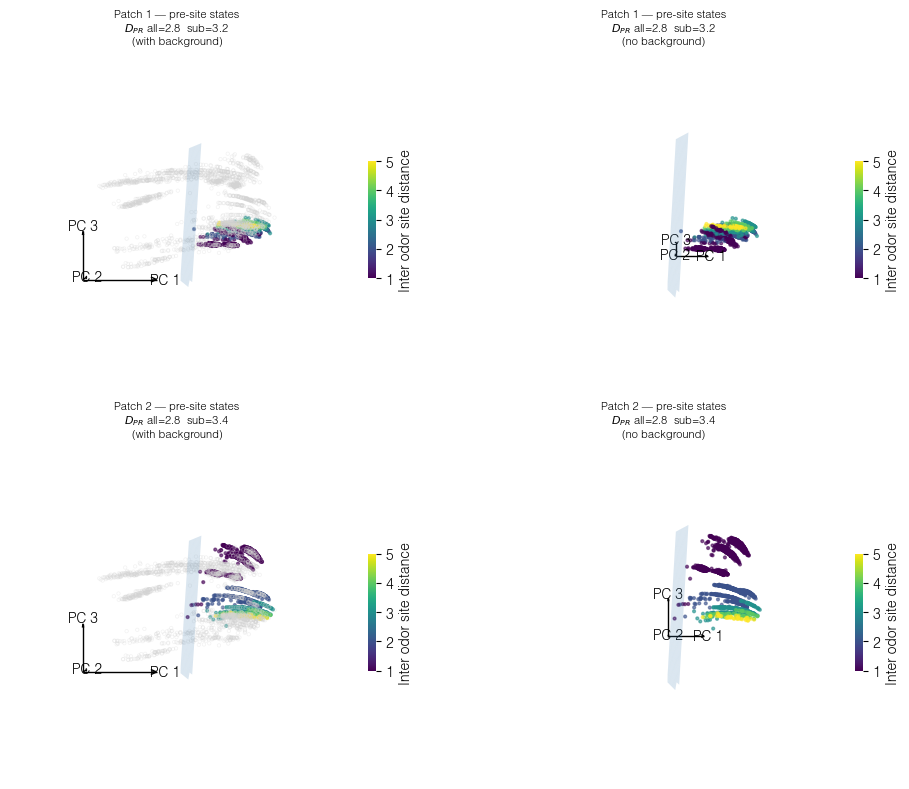

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [142]:
for net_idx, (dir_path, ckpt_path) in enumerate(zip(PASSING_NETWORKS, PASSING_CHECKPOINTS)):
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    network_name = Path(dir_path).parent.name
    save_dir = os.path.join('../../../figures', network_name)
    os.makedirs(save_dir, exist_ok=True)

    color_bys = ['inter_odor_site_distances', 'rewards_seen_in_patch', 'reward_site_idx']
    colorbar_labels = ['Inter odor site distance', 'Rewards seen in patch', 'Reward site']
    figs = [
        plot_pre_odor_site_states_3d(
            traj_data,
            pca,
            params=net_params,
            color_by=color_by,
            cbar_label=cbar_label,
            azim1=-90, elev1=0, azim2=-90, elev2=0,
            max_points=2000
        )
        for color_by, cbar_label in zip(color_bys, colorbar_labels)
    ]

    for color_by, fig in zip(color_bys, figs):
        plt.figure(fig.number) 
        fig.savefig(os.path.join(save_dir, f'pre_odor_site_states_3d_{color_by}.svg'), bbox_inches='tight')
        plt.show()

=== Network 0 ===


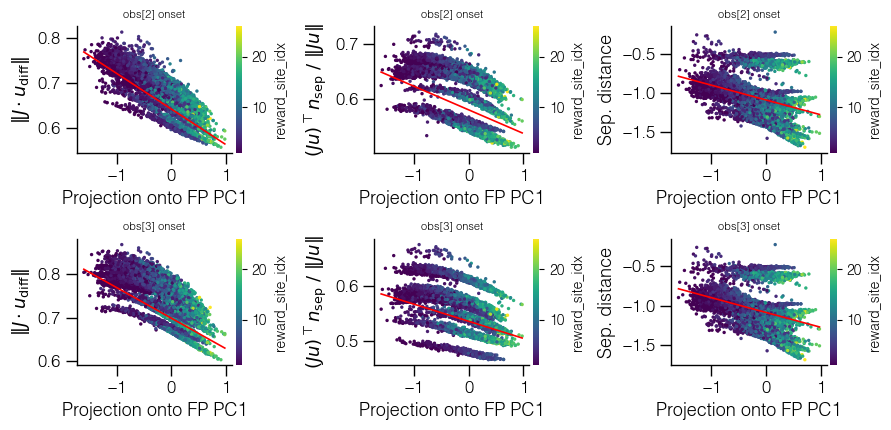

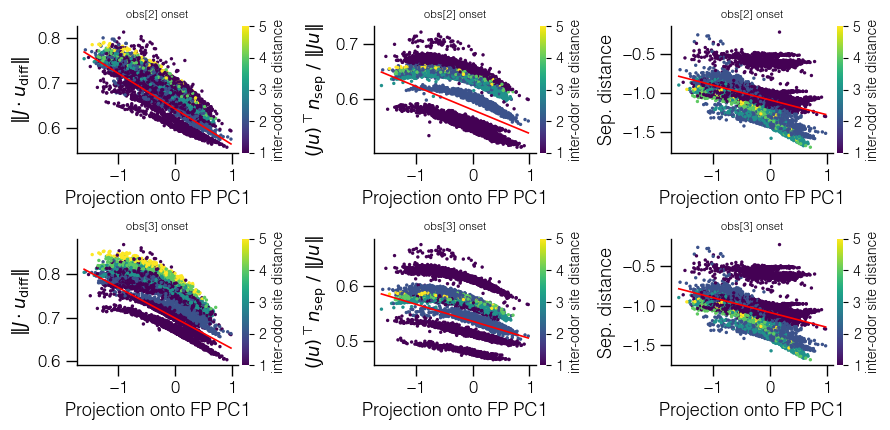

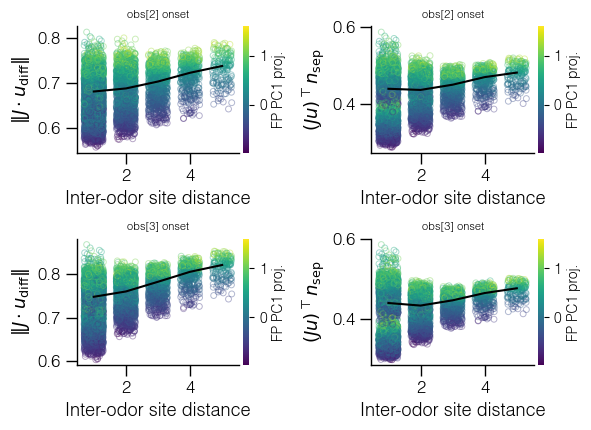

=== Network 1 ===


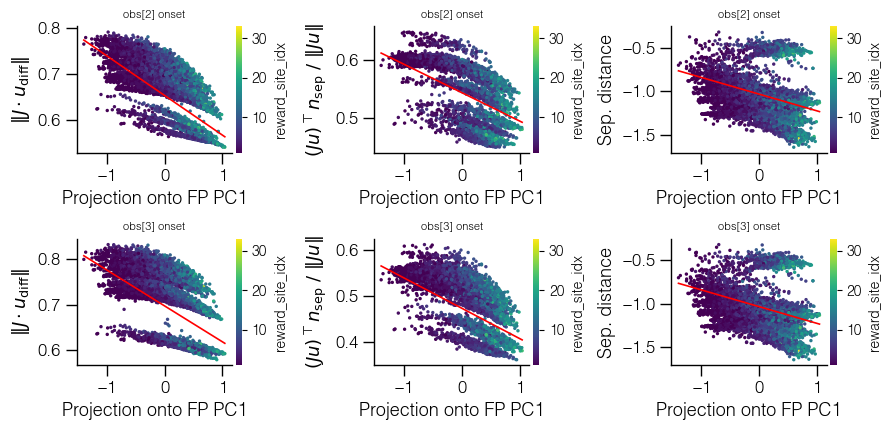

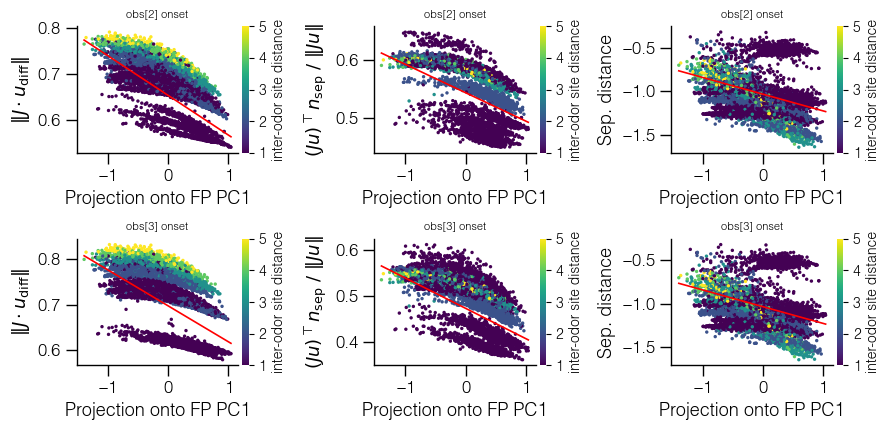

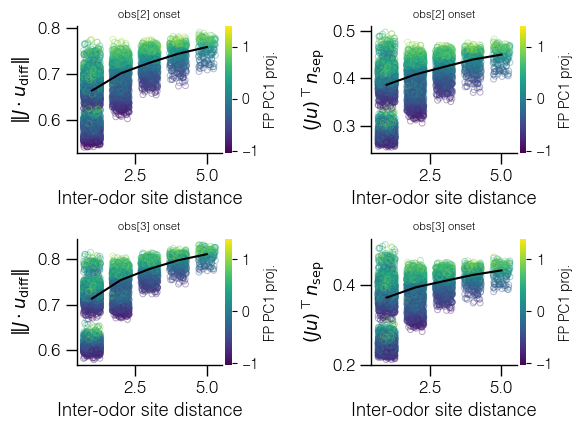

=== Network 2 ===


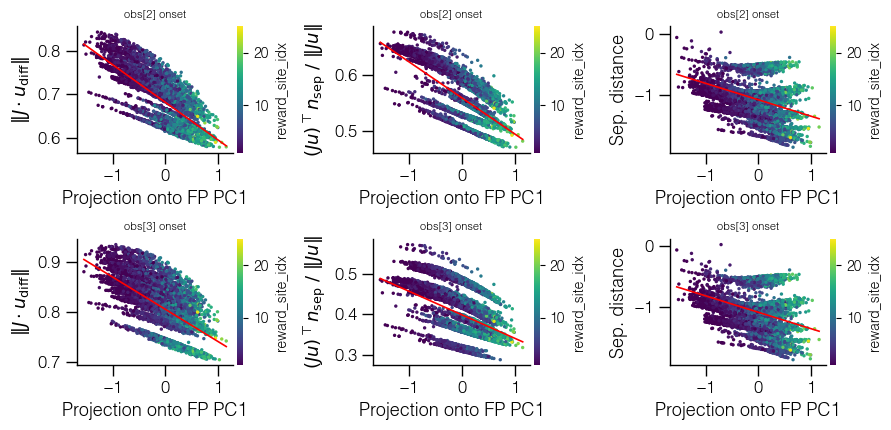

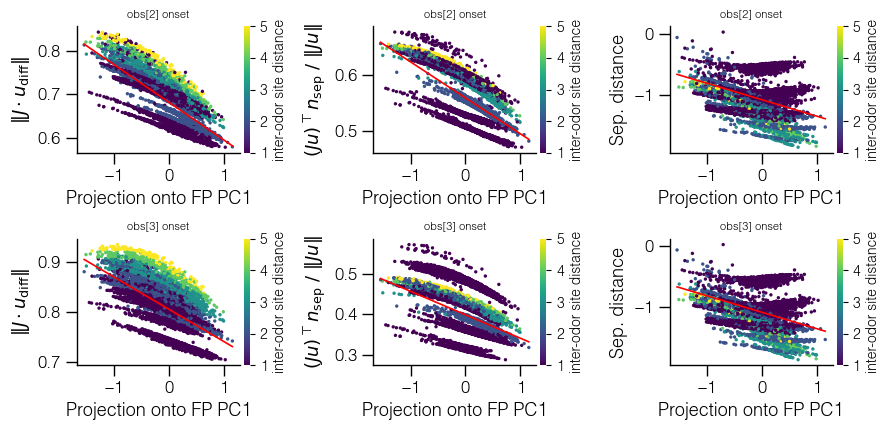

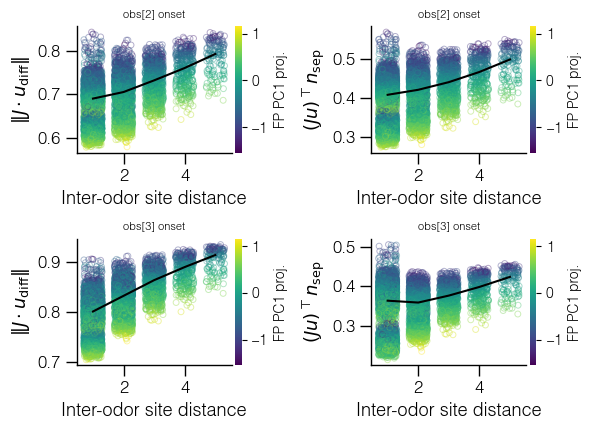

=== Network 3 ===


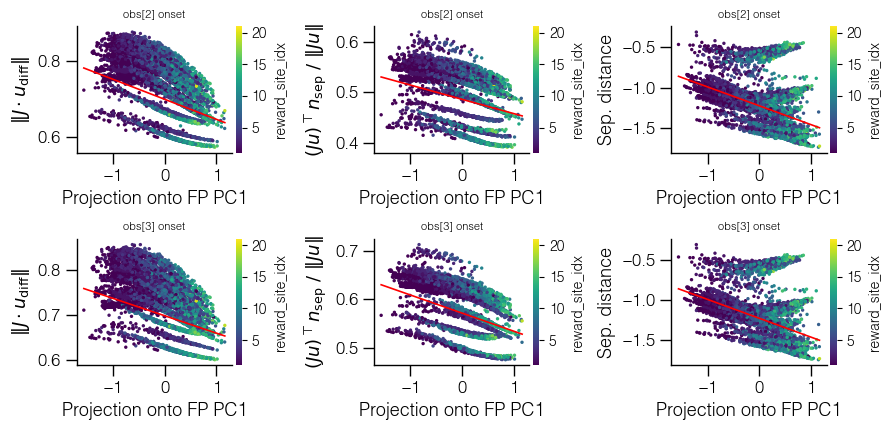

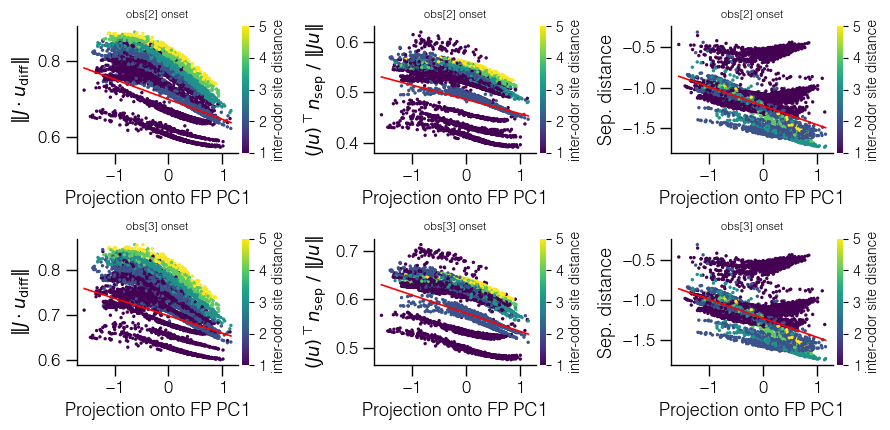

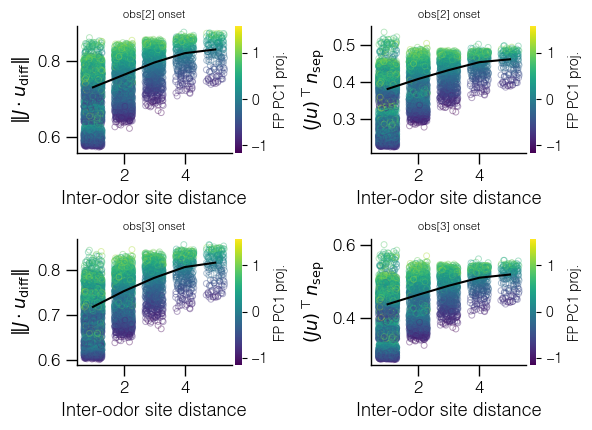

=== Network 4 ===


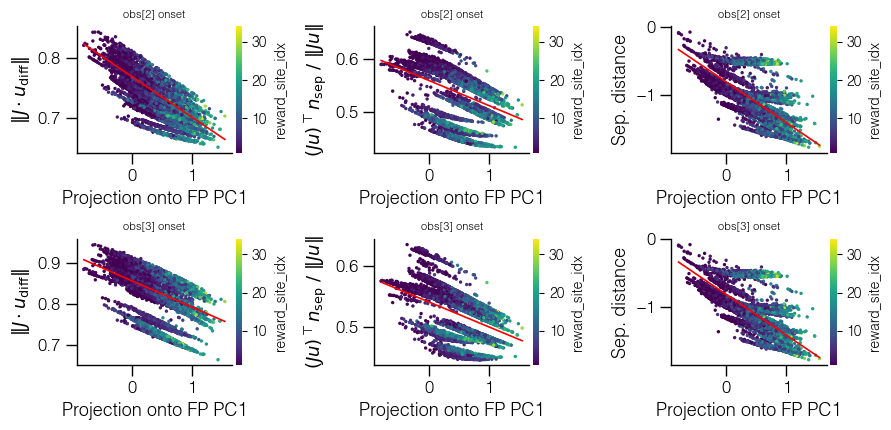

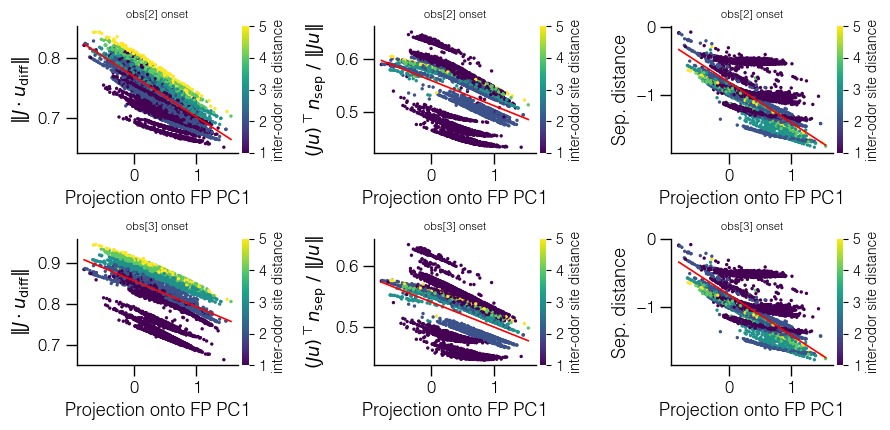

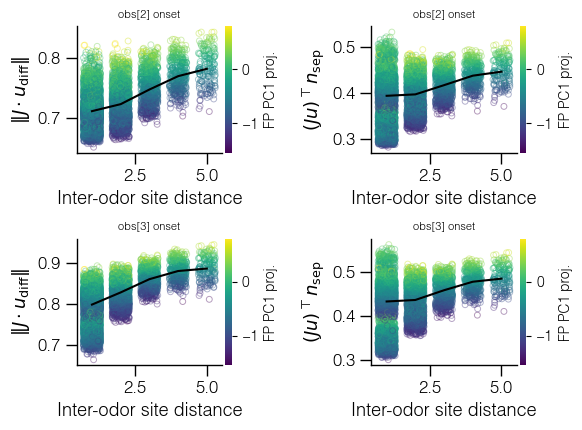

In [ ]:
all_jac2d_slopes = []
all_jac2d_ratios = []
for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(
        ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    # plot_pre_patch_states_jac_3d(traj_data, net_params, network, pca, azim=80, elev=70)
    save_base = f'../../../figures/gru_fixed_exp_decay_net_{net_idx}'
    os.makedirs(save_base, exist_ok=True)

    fig, slopes, ratios = plot_pre_patch_states_jac_2d(traj_data, net_params, network)
    all_jac2d_slopes.append(slopes)
    all_jac2d_ratios.append(ratios)
    fig.savefig(f'{save_base}/jac_2d_reward_site_idx.png', dpi=150, bbox_inches='tight')
    fig.savefig(f'{save_base}/jac_2d_reward_site_idx.svg', bbox_inches='tight')
    plt.show(fig)
    plt.close(fig)

    fig, slopes, ratios = plot_pre_patch_states_jac_2d(traj_data, net_params, network,
                                        color_by='inter_odor_site_distances',
                                        color_label='inter-odor site distance')
    fig.savefig(f'{save_base}/jac_2d_inter_odor.png', dpi=150, bbox_inches='tight')
    fig.savefig(f'{save_base}/jac_2d_inter_odor.svg', bbox_inches='tight')
    plt.show(fig)
    plt.close(fig)

    fig = plot_pre_patch_states_jac_2d_isi(traj_data, net_params, network)
    fig.savefig(f'{save_base}/jac_2d_isi.png', dpi=150, bbox_inches='tight')
    fig.savefig(f'{save_base}/jac_2d_isi.svg', bbox_inches='tight')
    plt.show(fig)
    plt.close(fig)

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


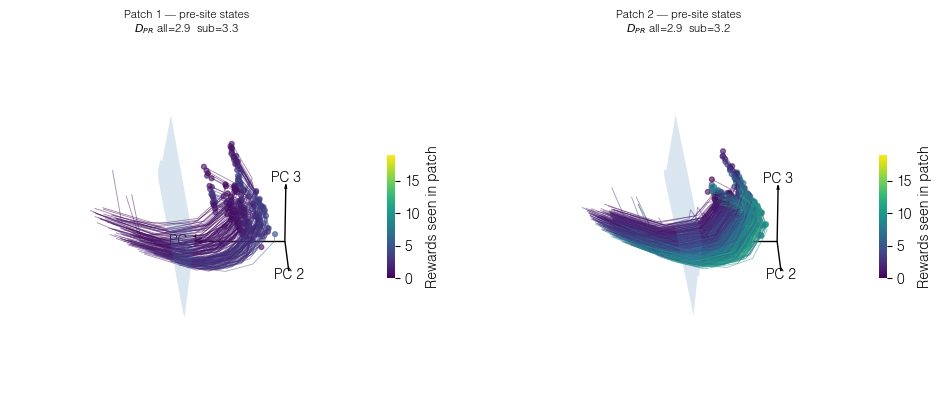

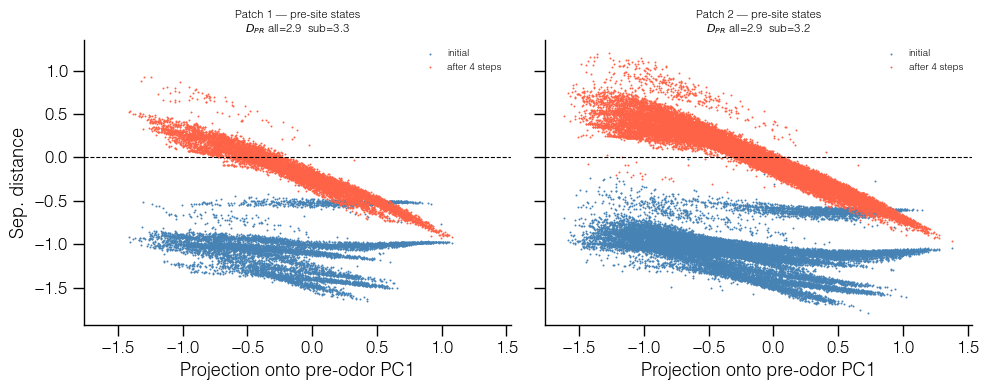

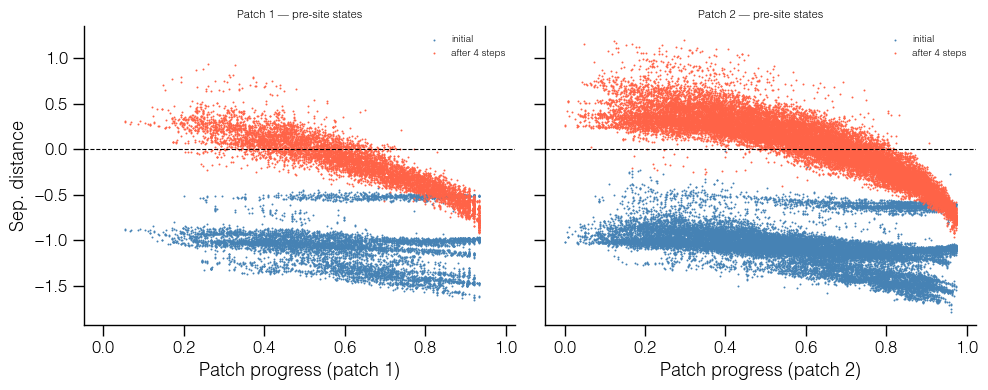

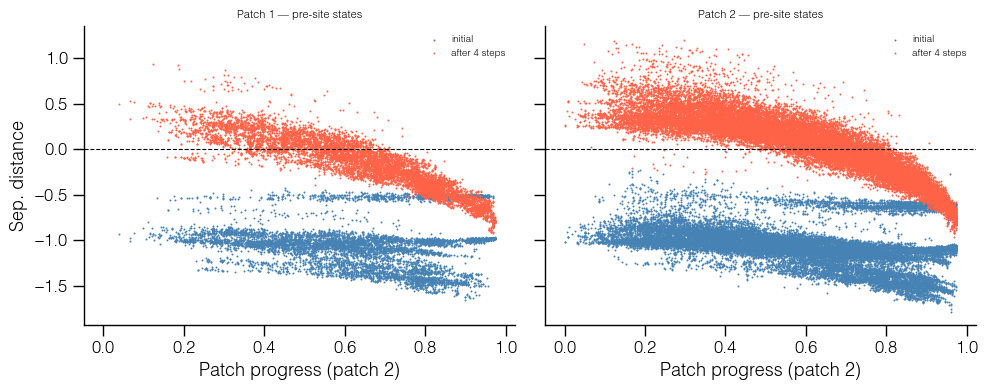

=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===


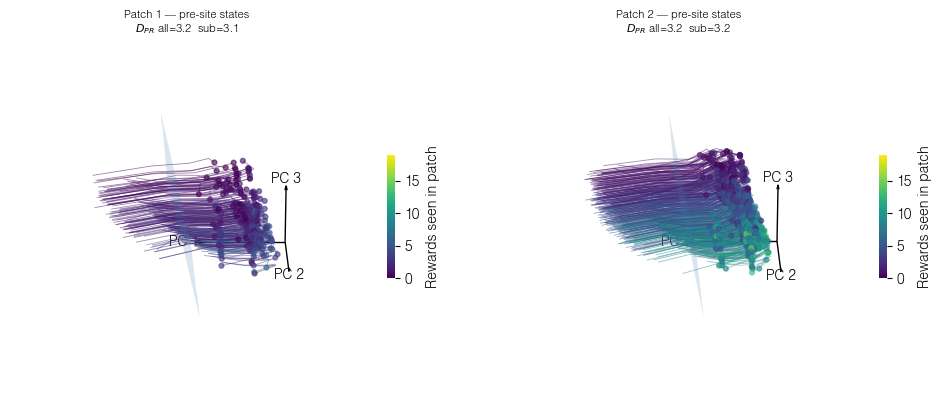

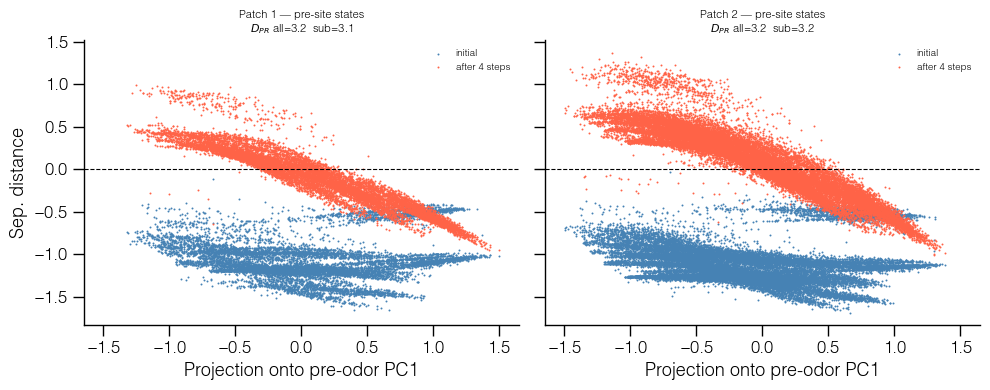

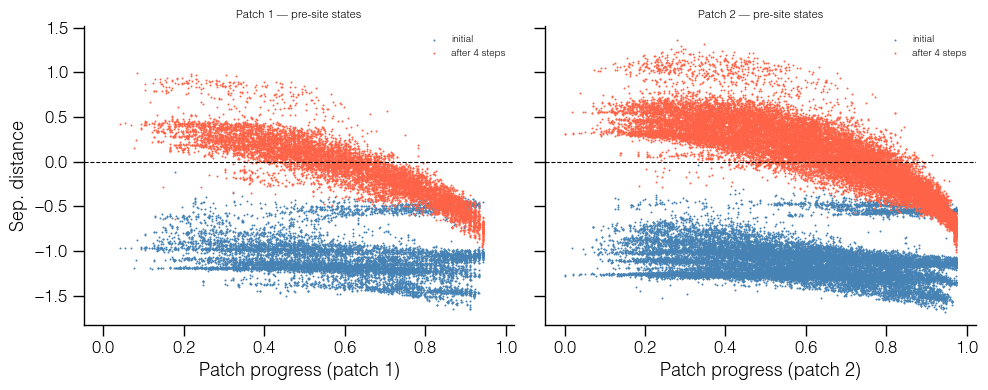

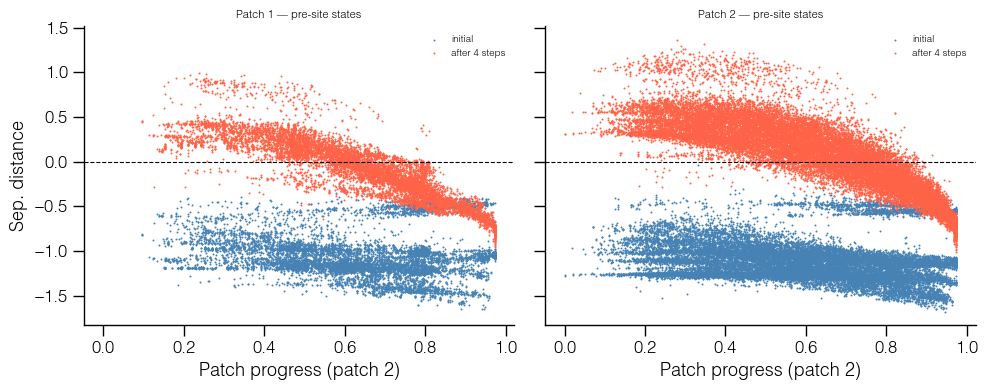

=== Network 2: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl ===


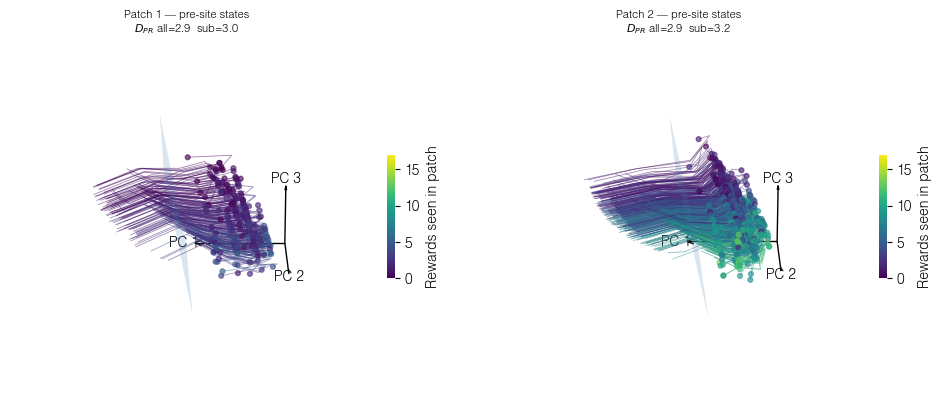

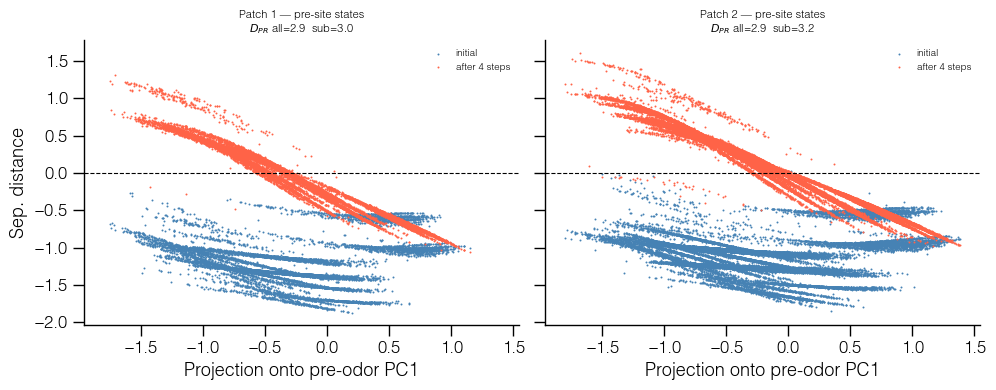

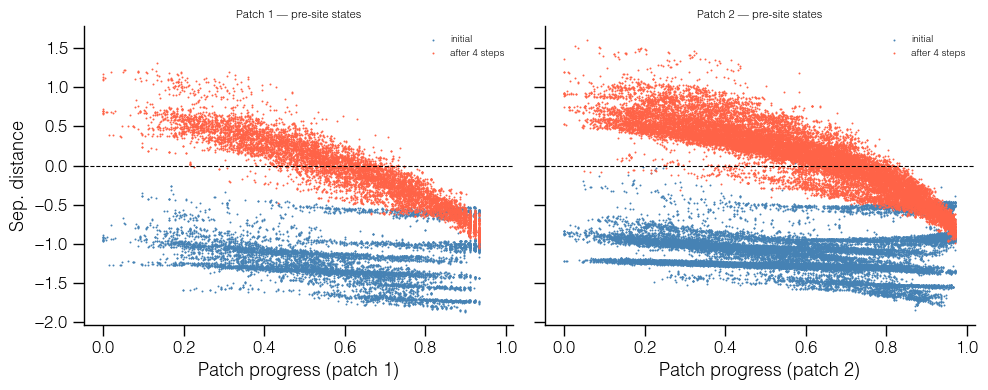

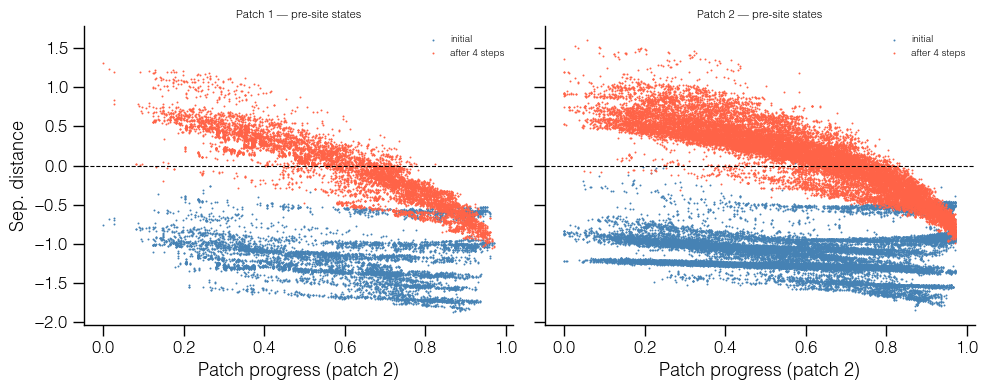

=== Network 3: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net3/trajectories_20260529_160251.pkl ===


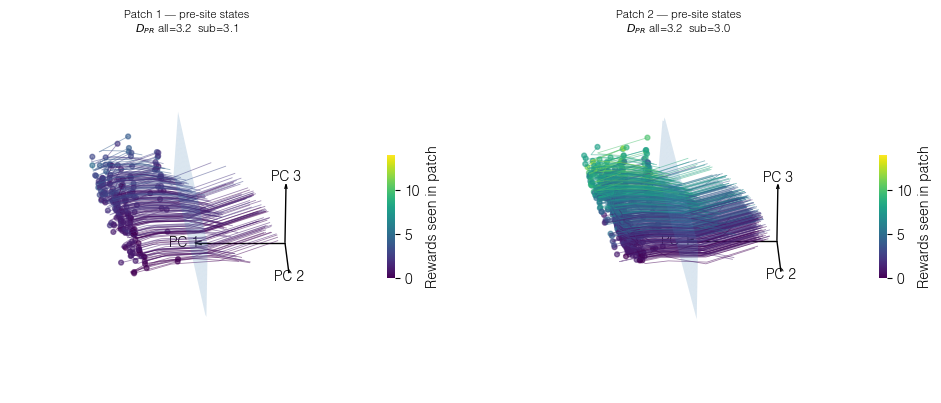

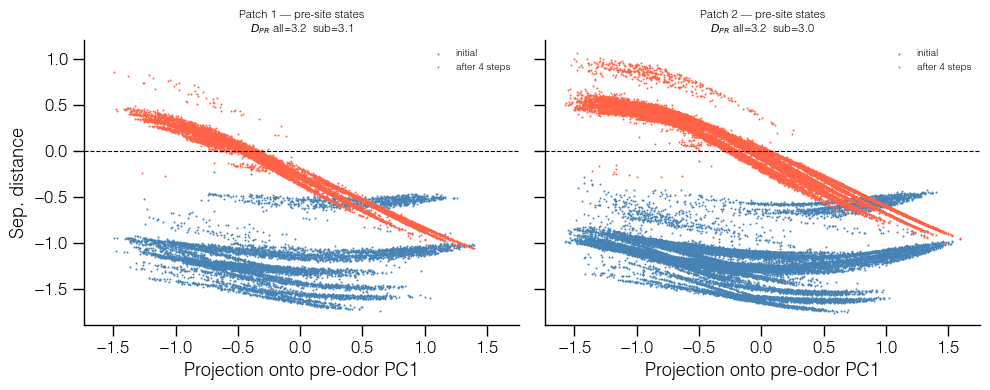

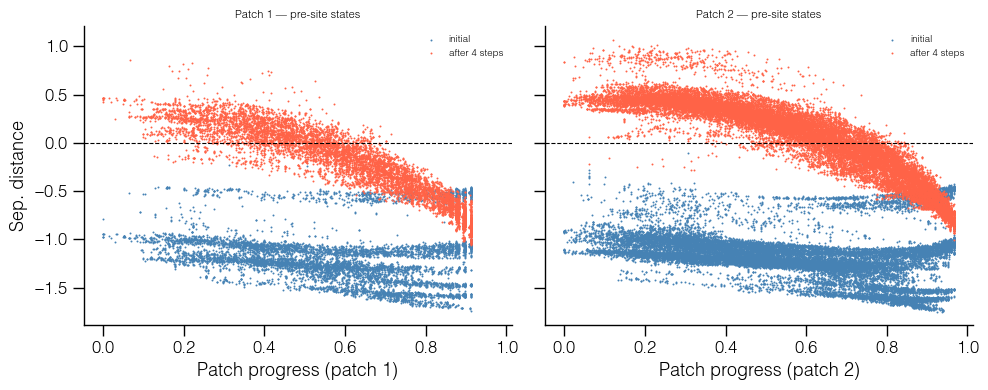

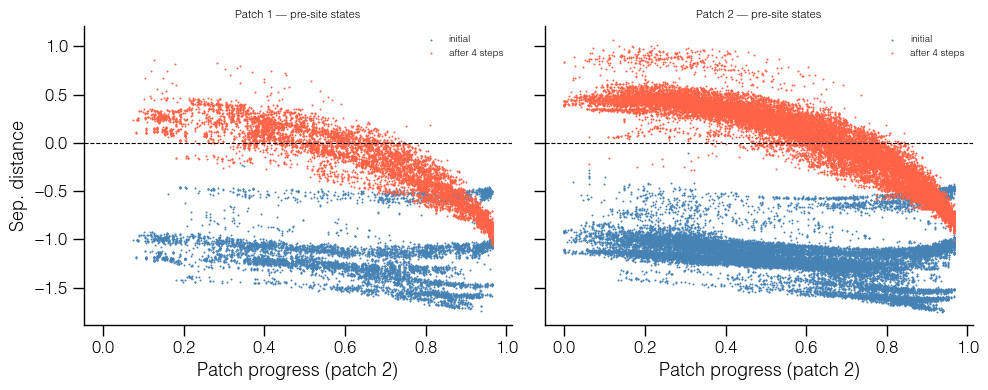

=== Network 4: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net4/trajectories_20260529_163734.pkl ===


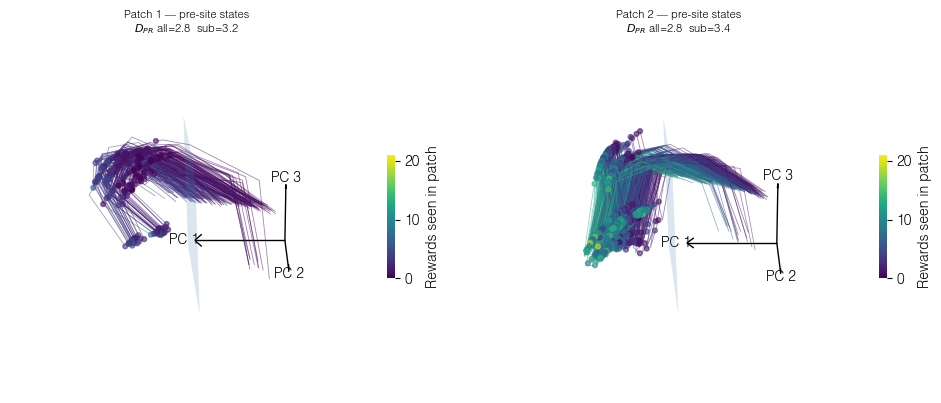

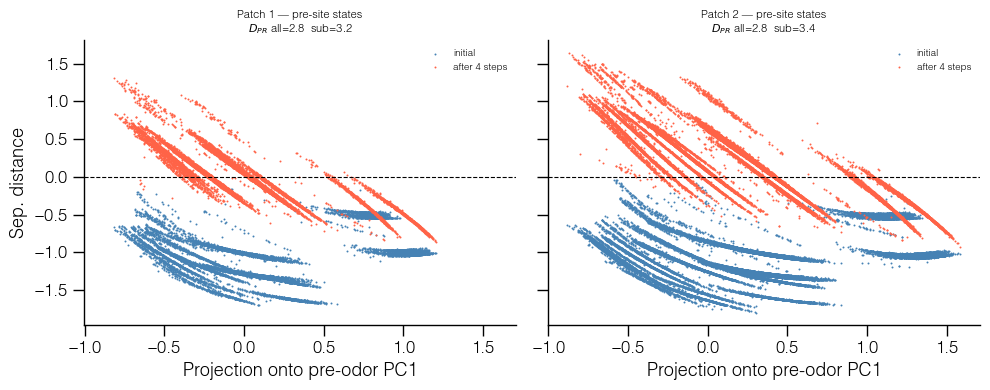

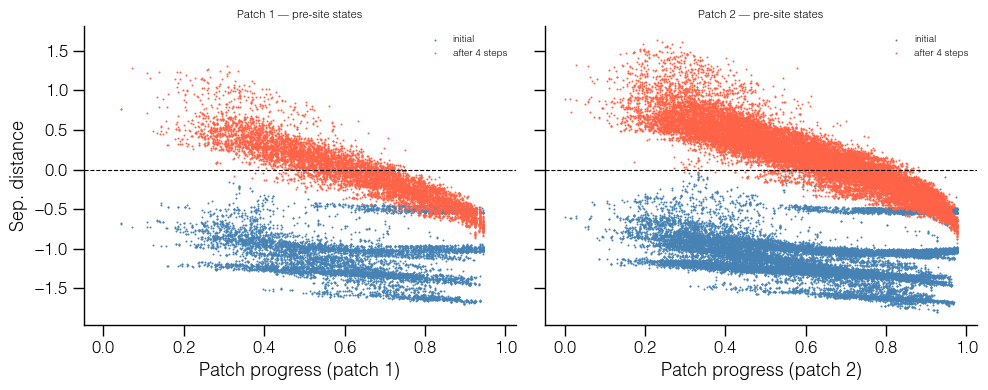

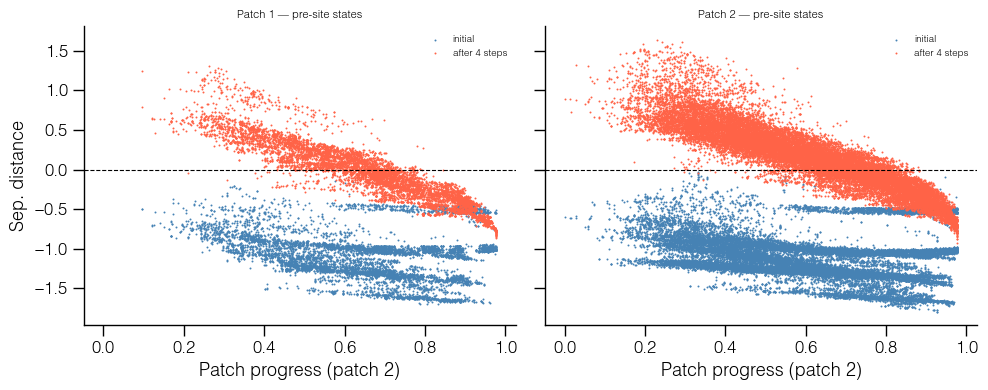

In [9]:
cov_sep_dist_isi_all = []

for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(
        ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    fig1, fig2, fig3, fig4, fig5 = plot_pre_patch_states_with_next_3d(
        traj_data,
        net_params,
        pca,
        color_by='rewards_seen_in_patch',
        cbar_label='Rewards seen in patch',
        azim=90,
        elev=20,
    )
    fig1.savefig(f'../../../figures/pre_patch_states_with_next_net{net_idx}.png',
                 dpi=300, bbox_inches='tight')
    plt.show(fig1); plt.close(fig1)
    fig2.savefig(f'../../../figures/pre_patch_sep_dist_net{net_idx}.png',
                 dpi=300, bbox_inches='tight')
    plt.show(fig2); plt.close(fig2)
    if fig3 is not None:
        fig3.savefig(f'../../../figures/pre_patch_fp_pc1_net{net_idx}.png',
                     dpi=300, bbox_inches='tight')
        plt.show(fig3); plt.close(fig3)
    fig4.savefig(f'../../../figures/pre_patch_progress_net{net_idx}.png',
                 dpi=300, bbox_inches='tight')
    plt.show(fig4); plt.close(fig4)
    fig5.savefig(f'../../../figures/pre_patch_progress_p2_net{net_idx}.png',
                 dpi=300, bbox_inches='tight')
    plt.show(fig5); plt.close(fig5)


### Trajectories of patch progress against time for rewarded odor contexts

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


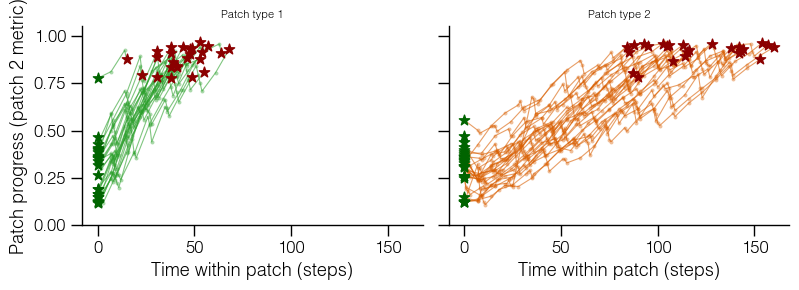

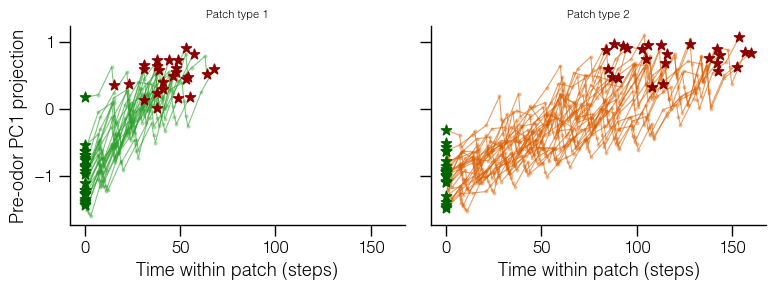

=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===


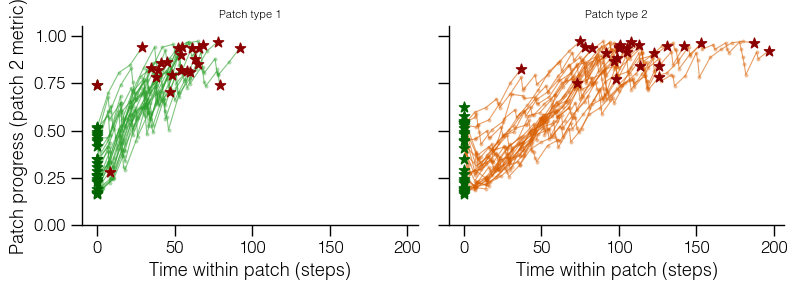

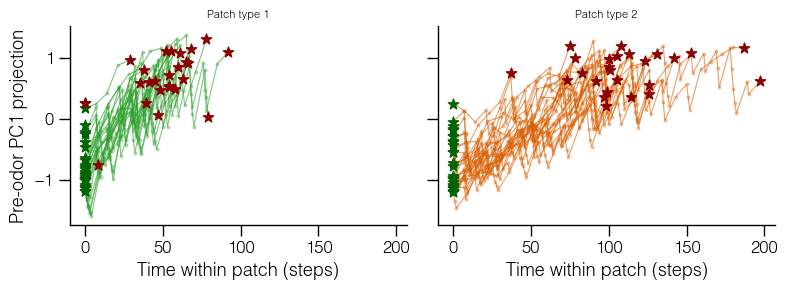

=== Network 2: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl ===


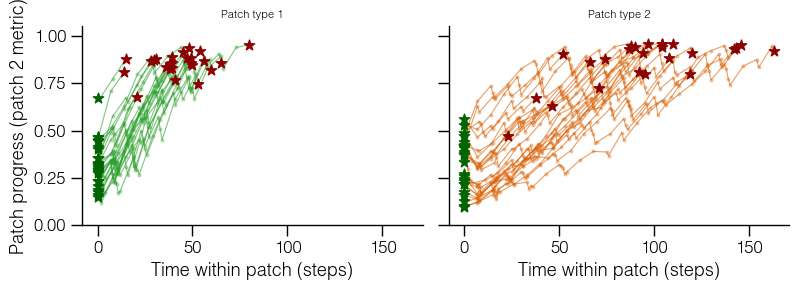

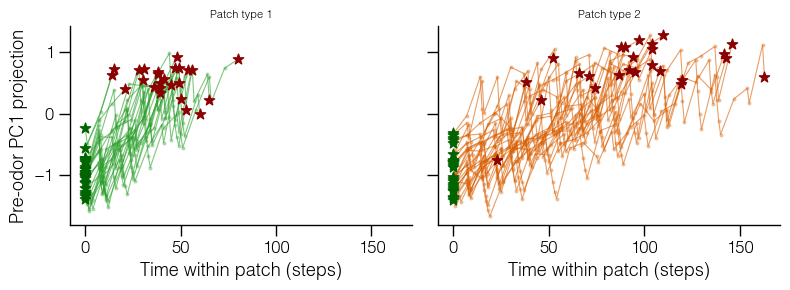

=== Network 3: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net3/trajectories_20260529_160251.pkl ===


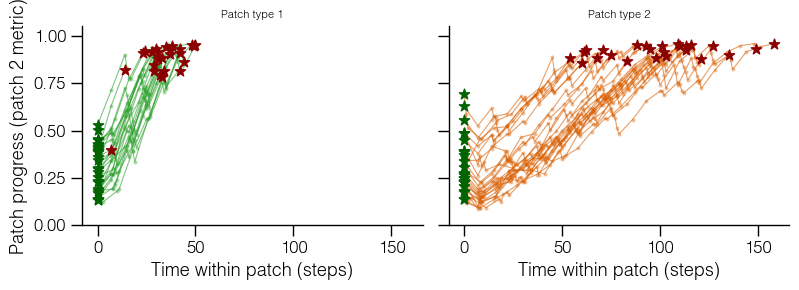

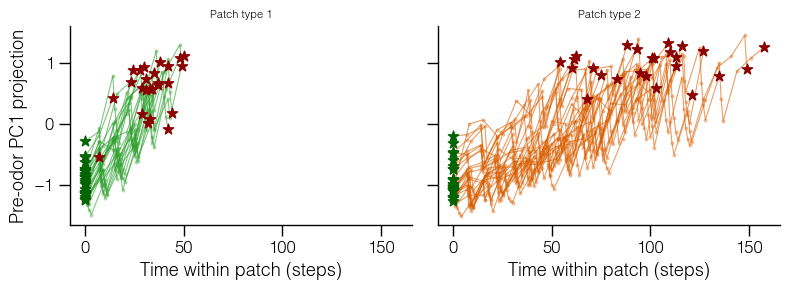

=== Network 4: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net4/trajectories_20260529_163734.pkl ===


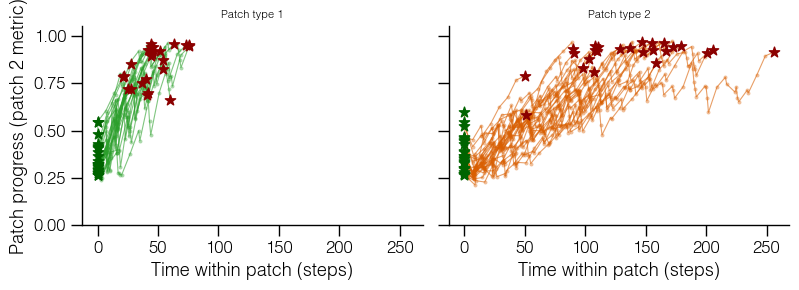

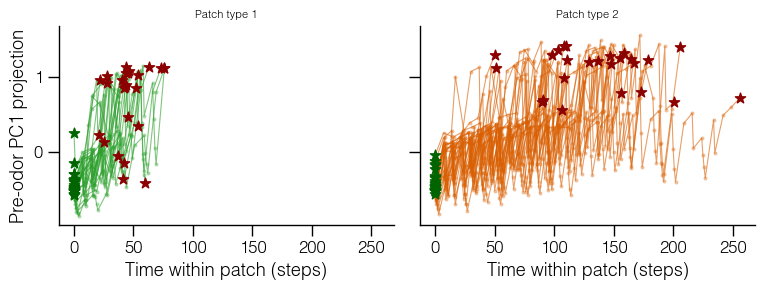

In [8]:
for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    fig = plot_patch_progress_trajectories(traj_data, patch_types=(1, 2), n_traj=25)
    if fig is not None:
        fig.savefig(f'../../../figures/patch_progress_trajectories_net{net_idx}.png',
                    dpi=300, bbox_inches='tight')
        plt.show(fig)
        plt.close(fig)

    fig_pc1 = plot_patch_progress_trajectories_pc1(traj_data, patch_types=(1, 2), n_traj=25)
    if fig_pc1 is not None:
        fig_pc1.savefig(f'../../../figures/patch_progress_trajectories_pc1_net{net_idx}.png',
                        dpi=300, bbox_inches='tight')
        plt.show(fig_pc1)
        plt.close(fig_pc1)


In [ ]:
# for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
#     print(f'=== Network {net_idx}: {dir_path} ===')

#     traj_data = {}
#     for env_idx in range(15):
#         traj_data_raw = load_trajectory_data(dir_path)
#         traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
#         for key in traj_data_env.keys():
#             if key in traj_data:
#                 traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
#             else:
#                 traj_data[key] = traj_data_env[key]

#     pca = PCA()
#     pca.fit(traj_data['actor_hidden'])
#     pc_activities = pca.transform(traj_data['actor_hidden'])

#     net_restored = checkpoints.restore_checkpoint(ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
#     net_params = net_restored.params

#     plot_patch_trajectories_3d(traj_data, color_by='reward_site_idx', max_trajectories=5, params=net_params, pca=pca, azim=130, elev=80)
#     plot_patch_activity_heatmaps(traj_data)
#     plot_pre_patch_states_3d(traj_data, pca, color_by='reward_site_idx')
#     plot_pre_patch_states_3d(traj_data, pca, color_by='inter_odor_site_distances')
#     plot_pre_patch_states_3d(traj_data, pca, color_by='rewards_seen_in_patch')
#     plot_pre_patch_states_3d(traj_data, pca, color_by='rewarded_last_odor_site')
#     plot_neuron_reward_correlations(traj_data)

=== Network 1 ===


  20 / 20 fixed points are stable


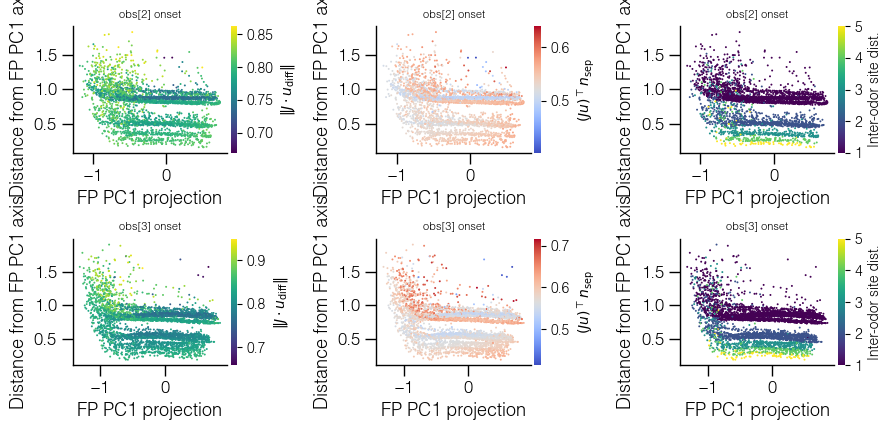

=== Network 2 ===


  13 / 18 fixed points are stable


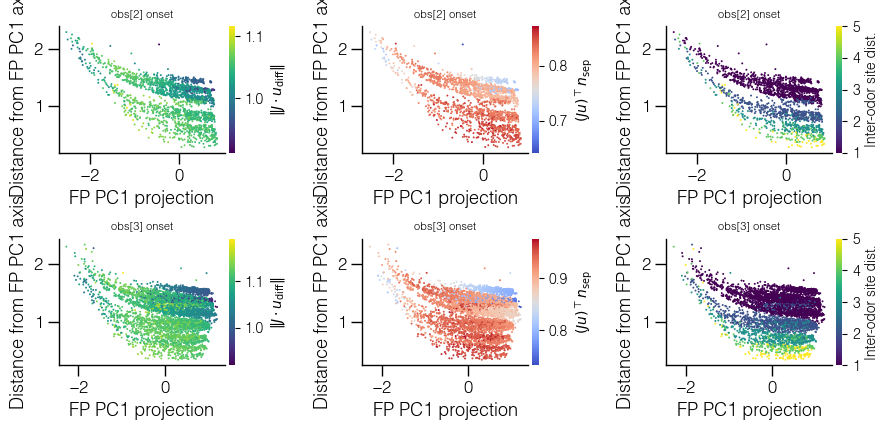

=== Network 4 ===


  13 / 17 fixed points are stable


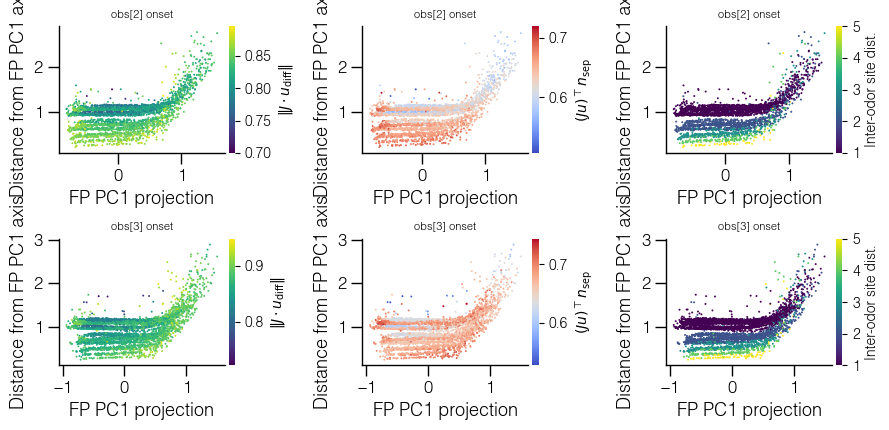

=== Network 5 ===


  13 / 13 fixed points are stable


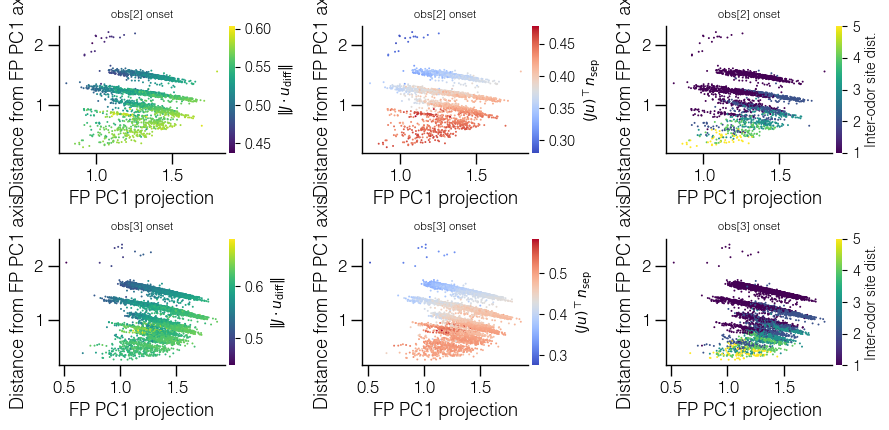

=== Network 6 ===


  24 / 24 fixed points are stable


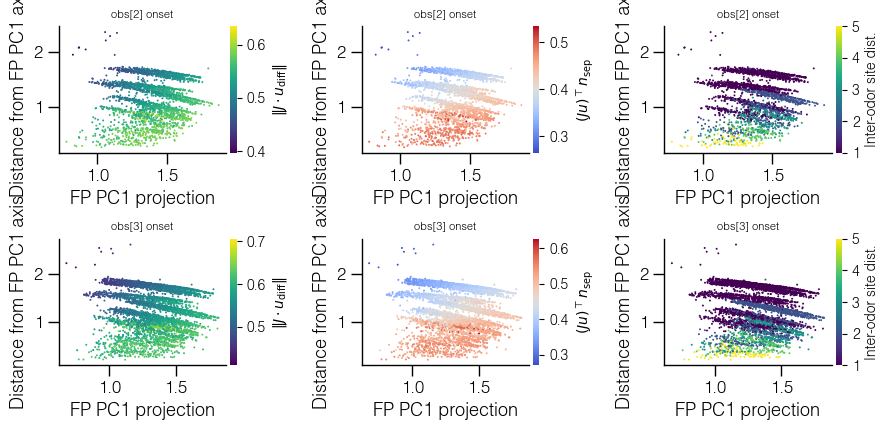

=== Network 7 ===


  18 / 18 fixed points are stable


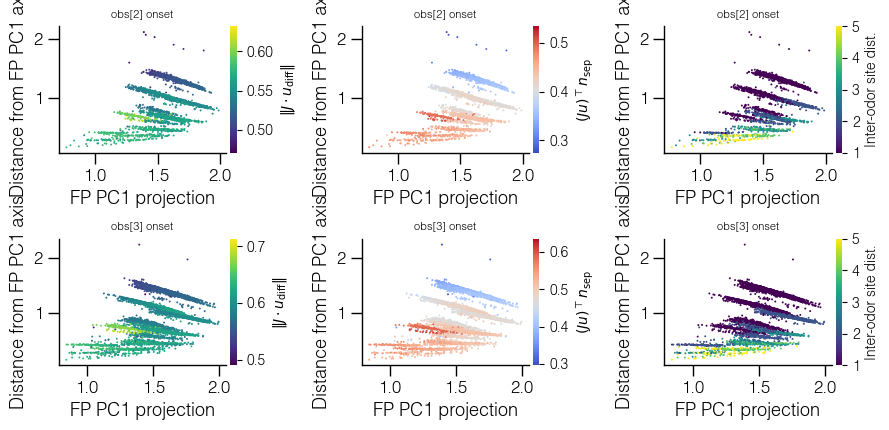

=== Network 8 ===


  1 / 2 fixed points are stable


/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/sklearn/decomposition/_pca.py:586: RuntimeWarning: invalid value encountered in divide
  explained_variance_ = (S**2) / (n_samples - 1)


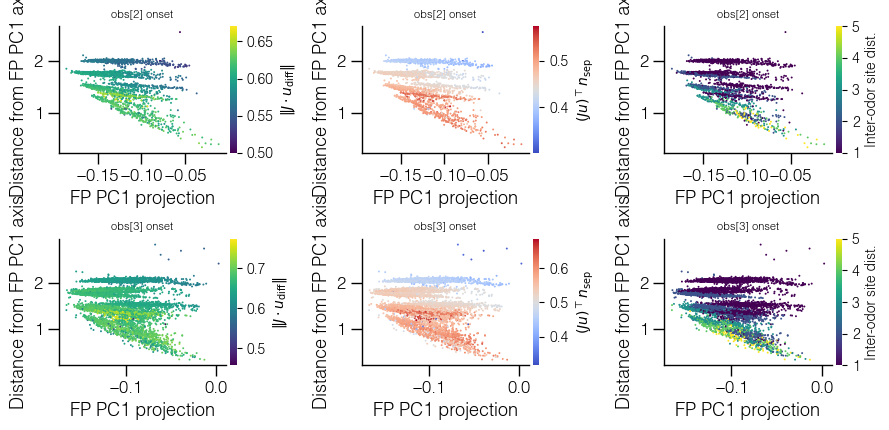

=== Network 9 ===


  19 / 19 fixed points are stable


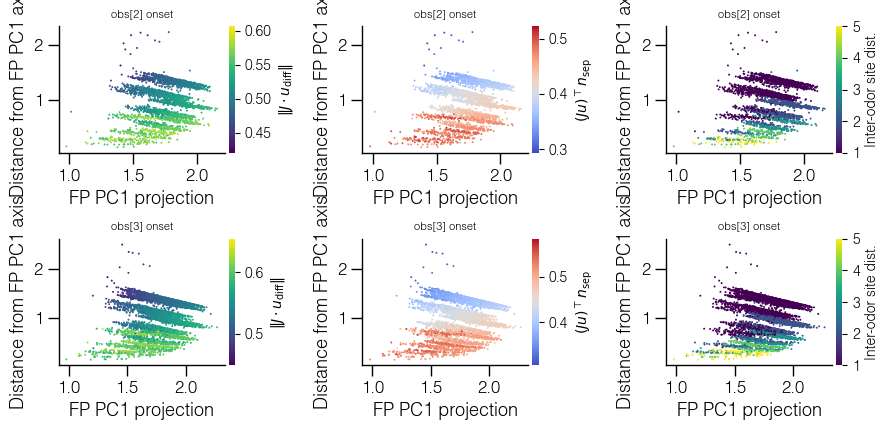

In [ ]:
for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    net_restored = checkpoints.restore_checkpoint(
        ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    plot_pre_patch_states_jac_pc1_space(traj_data, net_params, network)

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


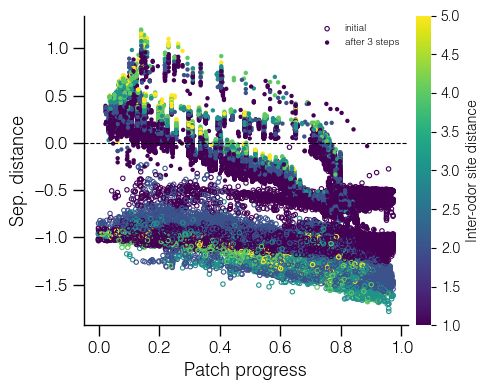

  4 / 4 fixed points stable


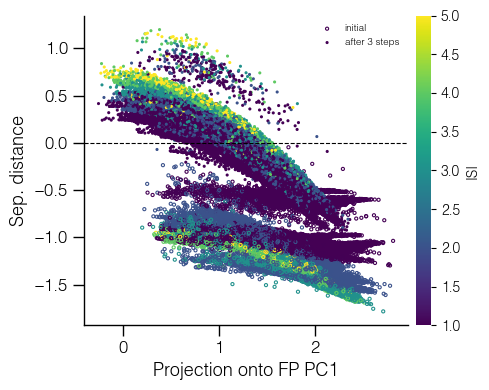

=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===


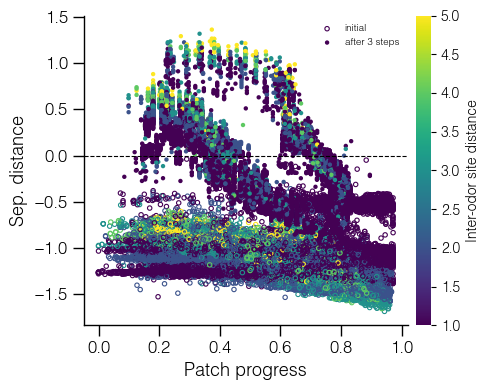

  6 / 6 fixed points stable


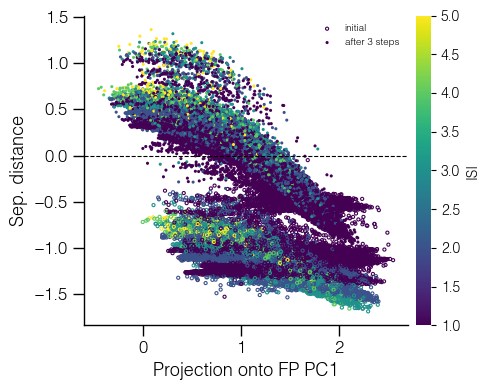

=== Network 2: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl ===


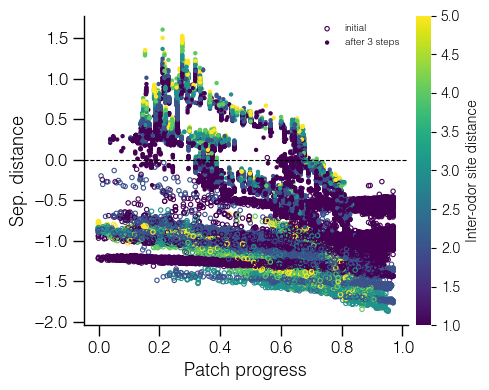

  4 / 4 fixed points stable


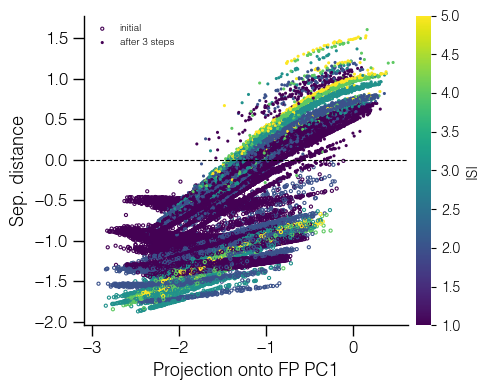

=== Network 3: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net3/trajectories_20260529_160251.pkl ===


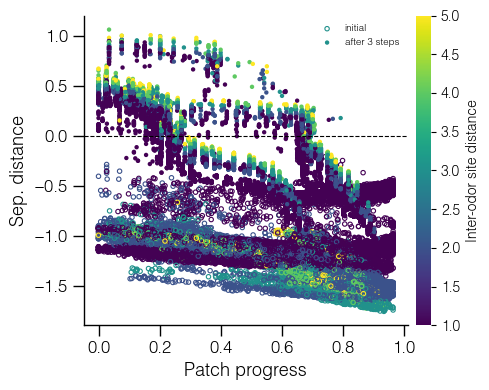

  6 / 6 fixed points stable


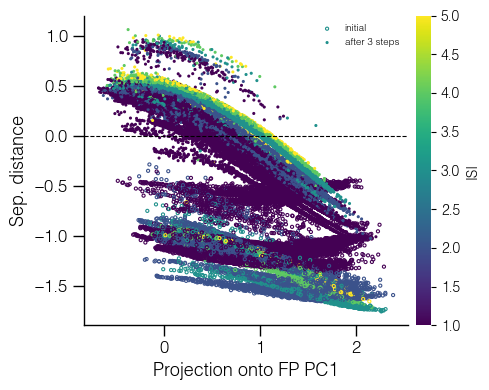

=== Network 4: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net4/trajectories_20260529_163734.pkl ===


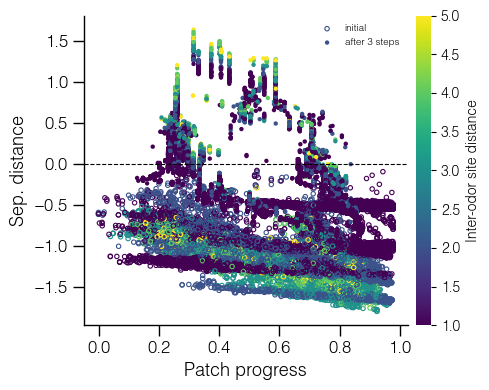

  5 / 5 fixed points stable


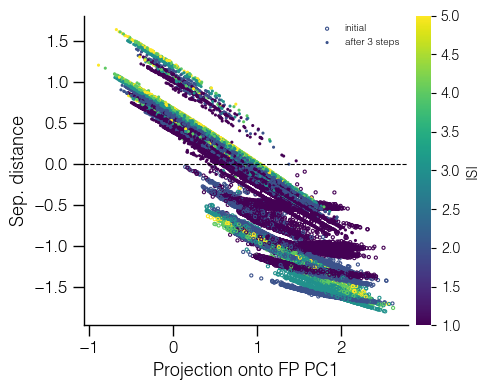

Covariance between sep dist and ISI across networks:


In [ ]:
cov_sep_dist_isi_all = []

for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(
        ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    fig_2d = plot_pre_patch_states_with_next_2d(traj_data, net_params)
    fig_2d.savefig(f'../../../figures/pre_patch_sep_dist_2d_net{net_idx}.png',
                   dpi=300, bbox_inches='tight')
    plt.show(fig_2d)
    plt.close(fig_2d)

    fig_fp_pc1 = plot_pre_patch_states_fp_pc1_2d(traj_data, net_params, network)
    fig_fp_pc1.savefig(f'../../../figures/pre_patch_fp_pc1_2d_net{net_idx}.png',
                       dpi=300, bbox_inches='tight')
    plt.show(fig_fp_pc1)
    plt.close(fig_fp_pc1)

    # fig_delta_sep, fig_delta_sep_groups, fig_delta_sep_pc1_lines, fig_delta_sep_delta_lines = plot_sep_dist_change_vs_isi(traj_data, net_params, n_groups=10)
    # fig_delta_sep.savefig(f'../../../figures/sep_dist_change_vs_isi_net{net_idx}.png',
    #                       dpi=300, bbox_inches='tight')
    # plt.show(fig_delta_sep)
    # plt.close(fig_delta_sep)
    # fig_delta_sep_groups.savefig(f'../../../figures/sep_dist_change_vs_isi_groups_net{net_idx}.png',
    #                              dpi=300, bbox_inches='tight')
    # plt.show(fig_delta_sep_groups)
    # plt.close(fig_delta_sep_groups)
    # fig_delta_sep_pc1_lines.savefig(f'../../../figures/sep_dist_final_vs_isi_pc1_lines_net{net_idx}.png',
    #                                 dpi=300, bbox_inches='tight')
    # plt.show(fig_delta_sep_pc1_lines)
    # plt.close(fig_delta_sep_pc1_lines)
    # fig_delta_sep_delta_lines.savefig(f'../../../figures/sep_dist_delta_vs_isi_pc1_lines_net{net_idx}.png',
    #                                   dpi=300, bbox_inches='tight')
    # plt.show(fig_delta_sep_delta_lines)
    # plt.close(fig_delta_sep_delta_lines)


print('Covariance between sep dist and ISI across networks:')
for idx, cov in enumerate(cov_sep_dist_isi_all):
    print(f'Net {idx}: {cov}')

=== Network 0 ===


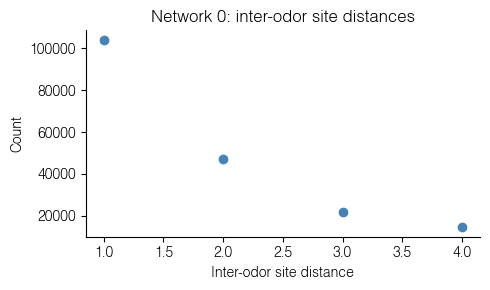

=== Network 1 ===


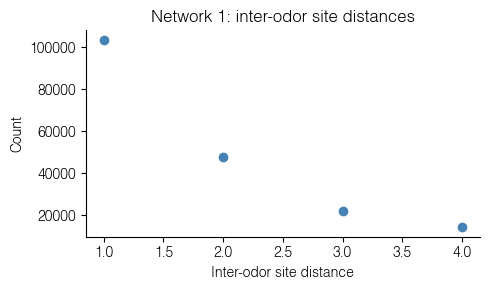

=== Network 2 ===


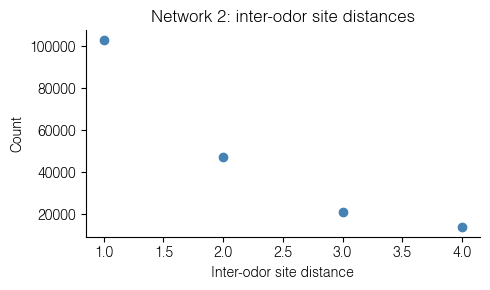

=== Network 3 ===


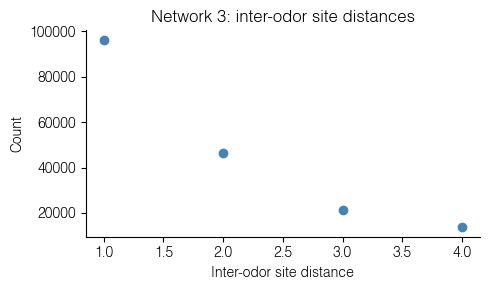

=== Network 4 ===


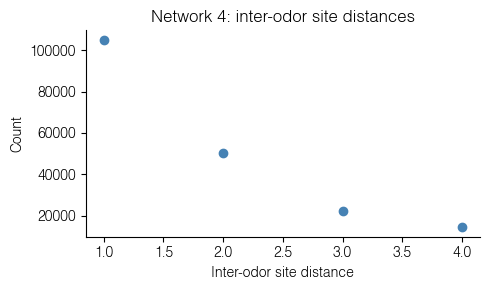

In [ ]:
for net_idx, dir_path in zip(passing_indices, PASSING_NETWORKS):
    print(f'=== Network {net_idx} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    inter_odor_site_distances = traj_data['inter_odor_site_distances']
    inter_odor_site_distances = inter_odor_site_distances[~np.isnan(inter_odor_site_distances)]
    inter_odor_site_distances = inter_odor_site_distances.astype(int)

    fig, ax = plt.subplots(figsize=(5, 3))
    counts, bins = np.histogram(inter_odor_site_distances, bins=np.unique(inter_odor_site_distances))
    ax.scatter(bins[:-1], counts, color='steelblue')
    ax.set_xlabel('Inter-odor site distance')
    ax.set_ylabel('Count')
    ax.set_title(f'Network {net_idx}: inter-odor site distances')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    plt.tight_layout()
    plt.show()


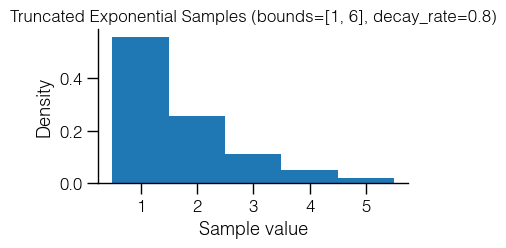

In [ ]:
from environments.treadmill_env_jax import sample_truncated_exp

n_samples = 10000
bounds = jnp.array([1.0, 6.0])
decay_rate = 0.8

rng_key = jax.random.PRNGKey(0)
sample_keys = jax.random.split(rng_key, n_samples)
samples = jax.vmap(lambda k: sample_truncated_exp(k, bounds, decay_rate))(sample_keys)

plt.figure(figsize=(4, 2))
plt.hist(samples.astype(int), bins=np.arange(1, 7) - 0.5, density=True)
plt.xlabel('Sample value')
plt.ylabel('Density')
plt.title('Truncated Exponential Samples (bounds=[1, 6], decay_rate=0.8)')
format_plot(plt.gca())
plt.show()

In [ ]:
OBS3_THRESHOLD = 0.5
MIN_GROUP_LEN  = 2   # skip groups too short to centre

group_pr_results = []
N_STEPS = 20000

for net_idx, dir_path in enumerate(FIXED_EXP_GRU_REWARD_DECAY_NETWORKS):
    print(f'Network {net_idx}...')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    obs_all    = traj_data['observations'].reshape(15, N_STEPS, -1)
    hidden_all = traj_data['actor_hidden'].reshape(15, N_STEPS, -1)

    for trial_idx in range(15):
        obs    = obs_all[trial_idx]    # (T, 4)
        hidden = hidden_all[trial_idx] # (T, H)

        # Locate patches via obs[:,0]
        in_patch = obs[:, 0] > OBS3_THRESHOLD
        padded   = np.concatenate([[False], in_patch, [False]])
        diff     = np.diff(padded.astype(int))
        p_starts = np.where(diff ==  1)[0]
        p_stops  = np.where(diff == -1)[0]

        for p_start, p_stop in zip(p_starts, p_stops):
            patch_obs    = obs[p_start:p_stop, :]      # (T_patch, 4)
            patch_hidden = hidden[p_start:p_stop, :]   # (T_patch, H)

            # Only include patches where obs[3] reaches ~1
            if not np.any(patch_obs[:, 3] > OBS3_THRESHOLD):
                continue

            # Low→high transitions of obs[3]
            obs3      = patch_obs[:, 3]
            rises     = np.where((obs3[:-1] <= OBS3_THRESHOLD) &
                                 (obs3[1:]  >  OBS3_THRESHOLD))[0] + 1

            if len(rises) == 0:
                continue  # obs[3] never rises — nothing to group

            # Groups: [rises[k], rises[k+1]), last group ends at T_patch
            group_edges = np.concatenate([rises, [len(obs3)]])
            groups = [(int(group_edges[k]), int(group_edges[k + 1]))
                      for k in range(len(group_edges) - 1)]

            # Centre each group and collect
            centred_groups = []
            for g_start, g_end in groups:
                H = patch_hidden[g_start:g_end]
                print(H.shape)
                if len(H) < MIN_GROUP_LEN:
                    continue
                print(H.shape)
                centred_groups.append(H - H.mean(axis=0))

            if len(centred_groups) < 2:
                continue  # need at least 2 groups for a meaningful comparison

            H_dim = centred_groups[0].shape[1]

            H_combined = np.vstack(centred_groups)
            pr = participation_ratio(H_combined)

            # Sequential control: unit t fires at step t within each group
            seq_groups = []
            for H_g in centred_groups:
                T_k = len(H_g)
                assert T_k <= H_dim, (
                    f"Group length {T_k} exceeds hidden dim {H_dim}")
                H_seq = np.zeros((T_k, H_dim))
                H_seq[np.arange(T_k), np.arange(T_k)] = 1.0
                seq_groups.append(H_seq - H_seq.mean(axis=0))

            pr_sequential = participation_ratio(np.vstack(seq_groups))

            group_pr_results.append({
                'net_idx':        net_idx,
                'trial_idx':      trial_idx,
                'n_groups':       len(centred_groups),
                'D_PR':           pr,
                'D_PR_sequential': pr_sequential,
            })

group_pr_df = pd.DataFrame(group_pr_results)
print(f'Collected {len(group_pr_df)} patches across all networks')
group_pr_df.head()

Network 0...
Loading trajectory data from: ../../results/fixed_exp_gru_reward_decay_net0/trajectories_20260409_181731.pkl
Loaded 30 episodes
Episode length: 20000
Observation shape: (20000, 4)
Action shape: (20000,)
Loading trajectory data from: ../../results/fixed_exp_gru_reward_decay_net0/trajectories_20260409_181731.pkl
Loaded 30 episodes
Episode length: 20000
Observation shape: (20000, 4)
Action shape: (20000,)
Loading trajectory data from: ../../results/fixed_exp_gru_reward_decay_net0/trajectories_20260409_181731.pkl
Loaded 30 episodes
Episode length: 20000
Observation shape: (20000, 4)
Action shape: (20000,)
Loading trajectory data from: ../../results/fixed_exp_gru_reward_decay_net0/trajectories_20260409_181731.pkl
Loaded 30 episodes
Episode length: 20000
Observation shape: (20000, 4)
Action shape: (20000,)
Loading trajectory data from: ../../results/fixed_exp_gru_reward_decay_net0/trajectories_20260409_181731.pkl
Loaded 30 episodes
Episode length: 20000
Observation shape: (20000

,net_idx,trial_idx,n_groups,D_PR,D_PR_sequential
0,0,0,22,2.338953,7.345279
1,0,0,23,2.300105,7.079509
2,0,0,20,2.614824,7.967423
3,0,0,21,2.296255,7.224583
4,0,0,22,2.302175,6.767591


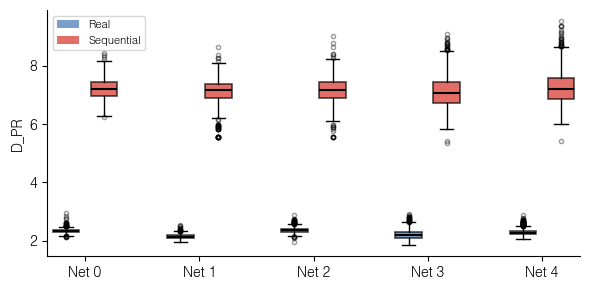

In [ ]:
net_indices = sorted(group_pr_df['net_idx'].unique())
n_nets = len(net_indices)

fig, ax = plt.subplots(figsize=(4 + n_nets * 0.4, 3))

positions_real = []
positions_seq  = []
data_real      = []
data_seq       = []

for k, net_idx in enumerate(net_indices):
    net = group_pr_df[group_pr_df['net_idx'] == net_idx]
    positions_real.append(k * 3 + 1)
    positions_seq.append(k * 3 + 2)
    data_real.append(net['D_PR'].values)
    data_seq.append(net['D_PR_sequential'].values)

bp_real = ax.boxplot(
    data_real, positions=positions_real, widths=0.7,
    patch_artist=True,
    medianprops={'color': 'black', 'linewidth': 1.5},
    boxprops={'linewidth': 1.2, 'facecolor': '#4575b4', 'alpha': 0.7},
    whiskerprops={'linewidth': 1.0},
    capprops={'linewidth': 1.0},
    flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.4},
)
bp_seq = ax.boxplot(
    data_seq, positions=positions_seq, widths=0.7,
    patch_artist=True,
    medianprops={'color': 'black', 'linewidth': 1.5},
    boxprops={'linewidth': 1.2, 'facecolor': '#d73027', 'alpha': 0.7},
    whiskerprops={'linewidth': 1.0},
    capprops={'linewidth': 1.0},
    flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.4},
)

tick_positions = [k * 3 + 1.5 for k in range(n_nets)]
ax.set_xticks(tick_positions)
ax.set_xticklabels([f'Net {i}' for i in net_indices])
ax.set_ylabel('D_PR')

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#4575b4', alpha=0.7, label='Real'),
    Patch(facecolor='#d73027', alpha=0.7, label='Sequential'),
], fontsize=8)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
for net_idx, (dir_path, ckpt_path) in enumerate(zip(
        FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS, FIXED_EXP_GRU_INITIAL_PROB_OFFSET_CHECKPOINTS)):
    network_name = Path(dir_path).parent.name
    print(f'=== Network {net_idx}: {network_name} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    net_restored = checkpoints.restore_checkpoint(
        ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])

    save_fixed_points_for_unique_inputs(
        traj_data=traj_data,
        params=net_params,
        network=network,
        save_dir='../../../saved_states',
        network_name=network_name,
        n_fp_attempts=1000,
        fp_tol=5e-1,
        min_occurrences=5,
        includes_actions_and_rewards=True,
        pca=pca,
        patch_idx=2,
    )


=== Network 0: fixed_exp_gru_initial_prob_offset_v4_net0 ===


12 unique input vectors; 11 have >= 5 occurrences
[1/12] 0_0_0_0_0_1_0  (count=23884)
  -> 568 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_0_0_0_0_0_1_0.pkl
[2/12] 0_0_0_0_1_0_0  (count=366)
  -> 625 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_0_0_0_0_1_0_0.pkl
[3/12] 1_0_0_0_0_1_0  (count=64386)
  -> 536 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_1_0_0_0_0_1_0.pkl
[4/12] 1_0_0_0_1_0_0  (count=52)
  -> 671 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_1_0_0_0_1_0_0.pkl
[5/12] 1_0_0_1_0_1_0  (count=77918)
  -> 720 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_1_0_0_1_0_1_0.pkl
[6/12] 1_0_0_1_1_0_0  (count=58006)
  -> 735 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_1_0_0_1

12 unique input vectors; 11 have >= 5 occurrences
[1/12] 0_0_0_0_0_1_0  (count=23412)
  -> 626 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_0_0_0_0_0_1_0.pkl
[2/12] 0_0_0_0_1_0_0  (count=566)
  -> 723 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_0_0_0_0_1_0_0.pkl
[3/12] 1_0_0_0_0_1_0  (count=64553)
  -> 641 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_1_0_0_0_0_1_0.pkl
[4/12] 1_0_0_0_1_0_0  (count=67)
  -> 743 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_1_0_0_0_1_0_0.pkl
[5/12] 1_0_0_1_0_1_0  (count=72466)
  -> 763 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_1_0_0_1_0_1_0.pkl
[6/12] 1_0_0_1_1_0_0  (count=53781)
  -> 788 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_1_0_0_1

12 unique input vectors; 11 have >= 5 occurrences
[1/12] 0_0_0_0_0_1_0  (count=24513)
  -> 577 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_0_0_0_0_0_1_0.pkl
[2/12] 0_0_0_0_1_0_0  (count=548)
  -> 654 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_0_0_0_0_1_0_0.pkl
[3/12] 1_0_0_0_0_1_0  (count=64130)
  -> 582 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_1_0_0_0_0_1_0.pkl
[4/12] 1_0_0_0_1_0_0  (count=72)
  -> 687 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_1_0_0_0_1_0_0.pkl
[5/12] 1_0_0_1_0_1_0  (count=74706)
  -> 687 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_1_0_0_1_0_1_0.pkl
[6/12] 1_0_0_1_1_0_0  (count=54879)
  -> 679 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_1_0_0_1

12 unique input vectors; 11 have >= 5 occurrences
[1/12] 0_0_0_0_0_1_0  (count=28959)
  -> 549 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_0_0_0_0_0_1_0.pkl
[2/12] 0_0_0_0_1_0_0  (count=512)
  -> 676 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_0_0_0_0_1_0_0.pkl
[3/12] 1_0_0_0_0_1_0  (count=64154)
  -> 546 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_1_0_0_0_0_1_0.pkl
[4/12] 1_0_0_0_1_0_0  (count=37)
  -> 678 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_1_0_0_0_1_0_0.pkl
[5/12] 1_0_0_1_0_1_0  (count=74997)
  -> 696 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_1_0_0_1_0_1_0.pkl
[6/12] 1_0_0_1_1_0_0  (count=54475)
  -> 733 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_1_0_0_1

12 unique input vectors; 11 have >= 5 occurrences
[1/12] 0_0_0_0_0_1_0  (count=21285)
  -> 429 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_0_0_0_0_0_1_0.pkl
[2/12] 0_0_0_0_1_0_0  (count=624)
  -> 570 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_0_0_0_0_1_0_0.pkl
[3/12] 1_0_0_0_0_1_0  (count=64787)
  -> 373 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_1_0_0_0_0_1_0.pkl
[4/12] 1_0_0_0_1_0_0  (count=143)
  -> 514 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_1_0_0_0_1_0_0.pkl
[5/12] 1_0_0_1_0_1_0  (count=77677)
  -> 550 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_1_0_0_1_0_1_0.pkl
[6/12] 1_0_0_1_1_0_0  (count=58698)
  -> 611 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_1_0_0_

### Generate animations of patch trajectories

In [ ]:
for net_idx, (dir_path, ckpt_path) in enumerate(zip(FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS, FIXED_EXP_GRU_INITIAL_PROB_OFFSET_CHECKPOINTS)):
    if net_idx != 0:
        continue
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    animate_patch_trajectories_3d(
        traj_data,
        max_trajectories=1,
        params=net_params,
        pca=pca,
        rx1=20, ry1=0, rz1=80,
        rx2=110, ry2=0, rz2=70,
        steps_per_frame=0.5,
        rotation=True,
        save_path=Path(dir_path).parent.resolve() / f'animated_patch_trajectories_{env_idx}.mp4',
        dpi=500,
    )

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


ffmpeg not found — saving as GIF instead: /home/david.bell/work/favorably_connected_2/results/fixed_exp_gru_initial_prob_offset_v4_net0/animated_patch_trajectories_14.gif
Saved to /home/david.bell/work/favorably_connected_2/results/fixed_exp_gru_initial_prob_offset_v4_net0/animated_patch_trajectories_14.gif


### Fixed-point dynamics across training (structure_evo_exp_gru_initial_prob_offset)

Found 80 traj/checkpoint pairs
Selected 12 pairs at sessions: [0, 25, 50, 75, 100, 125, 150, 175, 200, 500, 900, 1900]
Session 0: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000000.pkl


Trial 0, patch 3  (global steps 741–778, length 38)  → 38 segments with ≥2 steps


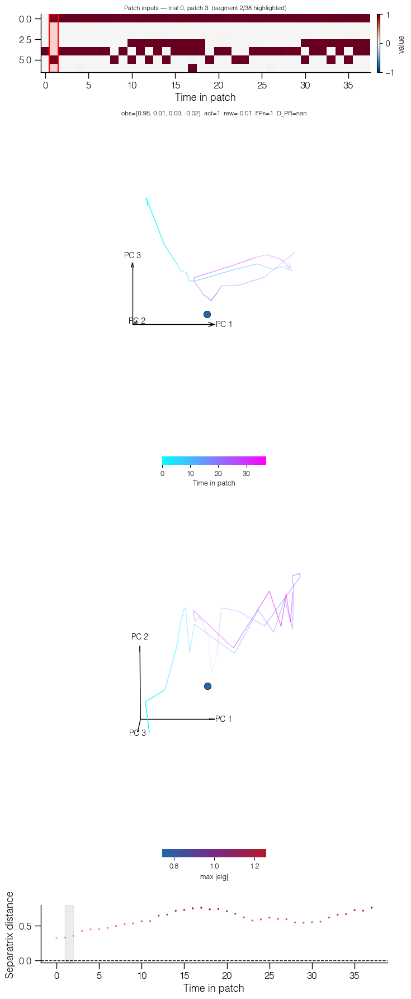

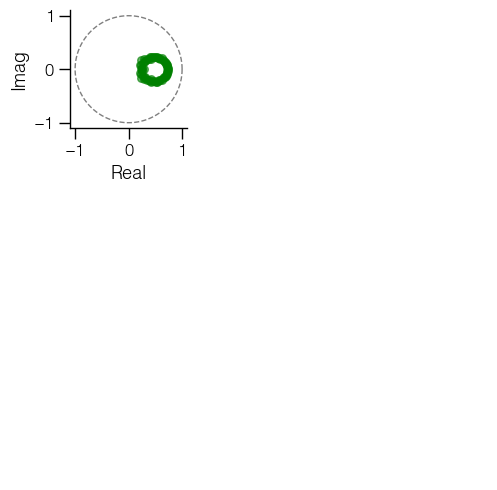

<Figure size 640x480 with 0 Axes>

Session 25: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000025.pkl


Trial 0, patch 3  (global steps 173–342, length 170)  → 170 segments with ≥2 steps


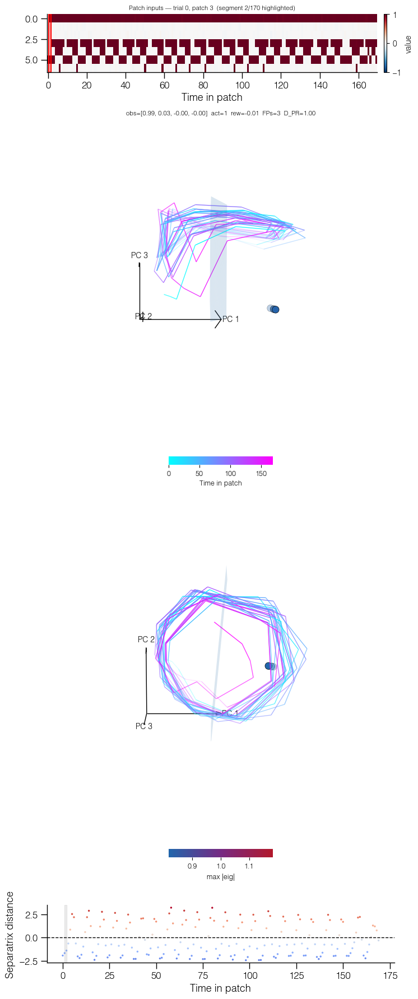

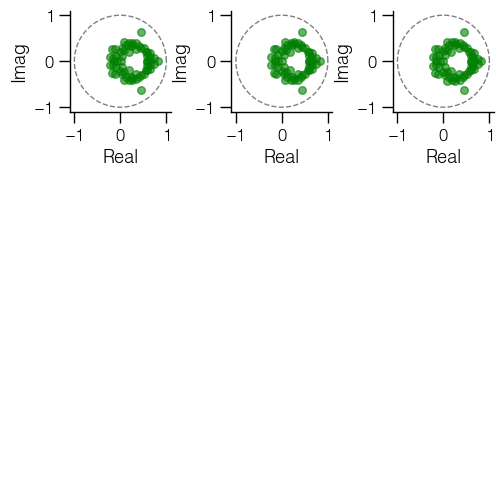

<Figure size 640x480 with 0 Axes>

Session 50: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000050.pkl


Trial 0, patch 3  (global steps 718–886, length 169)  → 169 segments with ≥2 steps


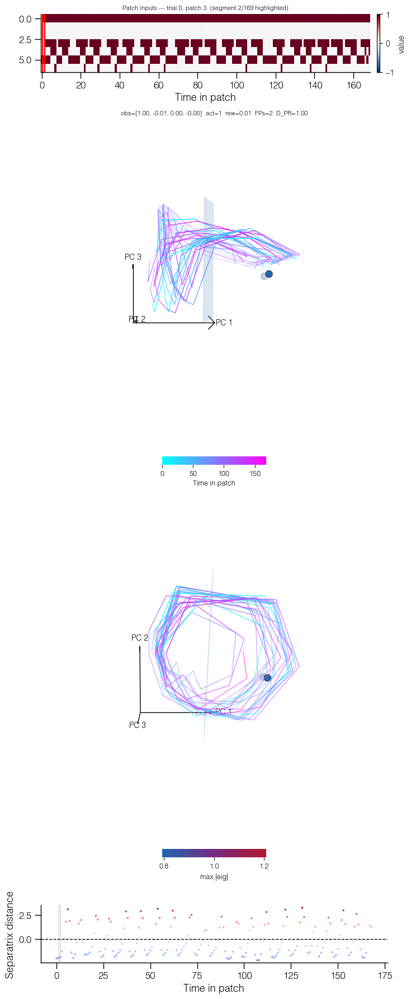

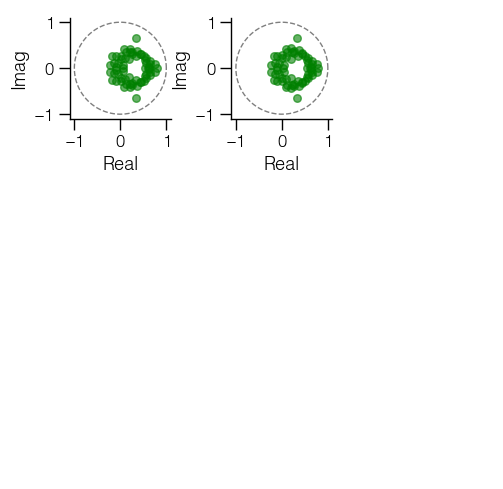

<Figure size 640x480 with 0 Axes>

Session 75: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000075.pkl


Trial 0, patch 3  (global steps 801–870, length 70)  → 70 segments with ≥2 steps


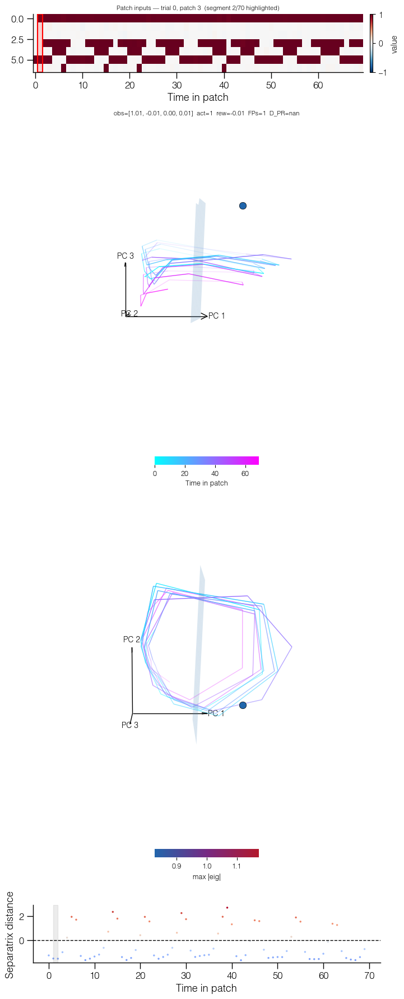

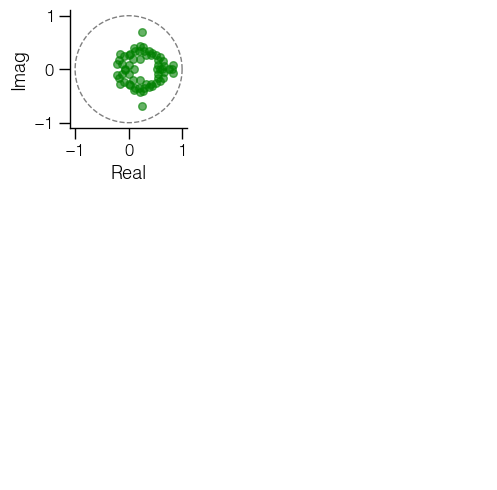

<Figure size 640x480 with 0 Axes>

Session 100: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000100.pkl


Trial 0, patch 3  (global steps 887–996, length 110)  → 110 segments with ≥2 steps


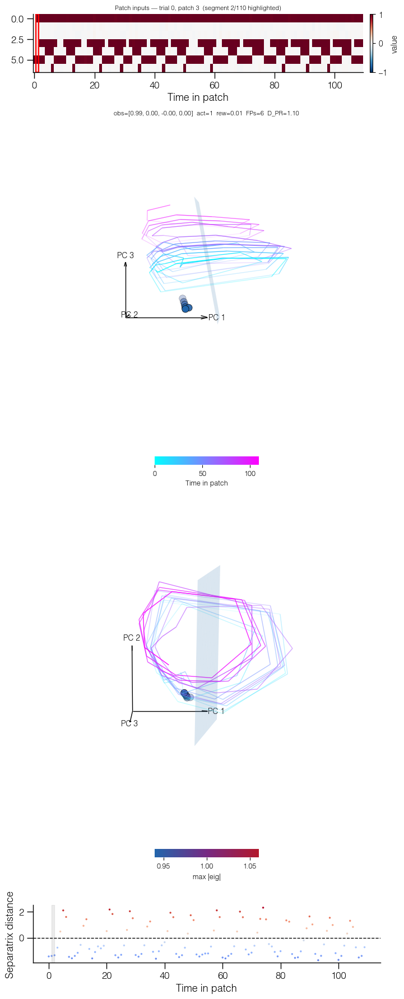

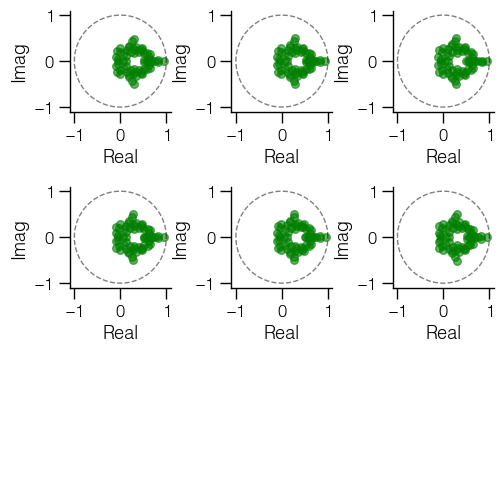

<Figure size 640x480 with 0 Axes>

Session 125: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000125.pkl


Trial 0, patch 3  (global steps 587–768, length 182)  → 182 segments with ≥2 steps


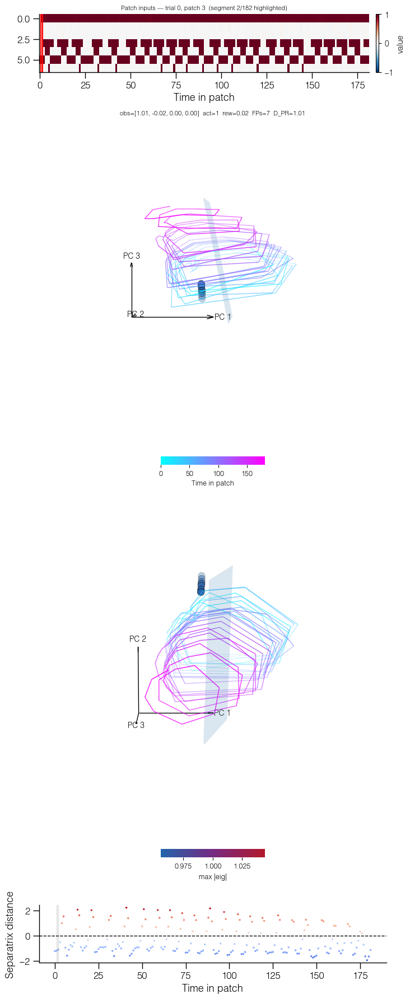

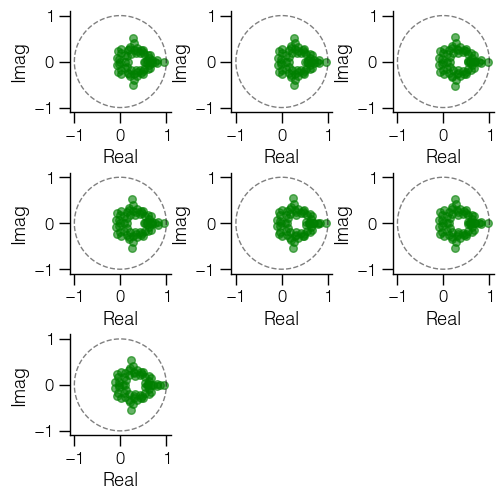

<Figure size 640x480 with 0 Axes>

Session 150: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000150.pkl


Trial 0, patch 3  (global steps 489–599, length 111)  → 111 segments with ≥2 steps


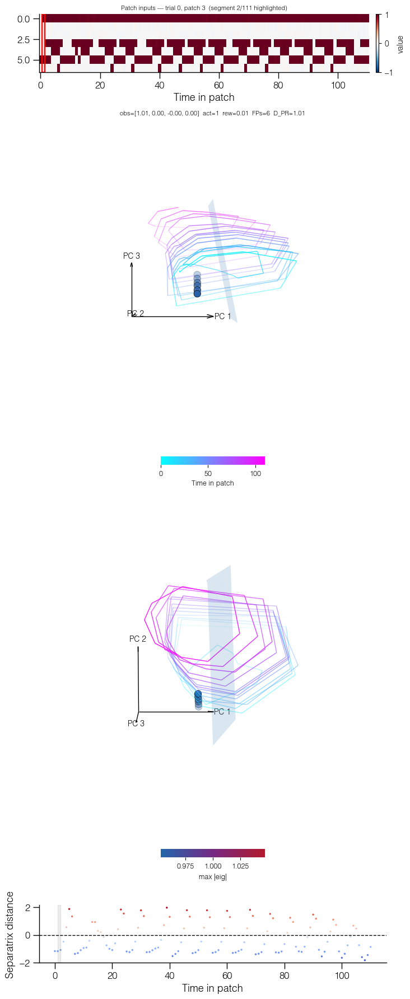

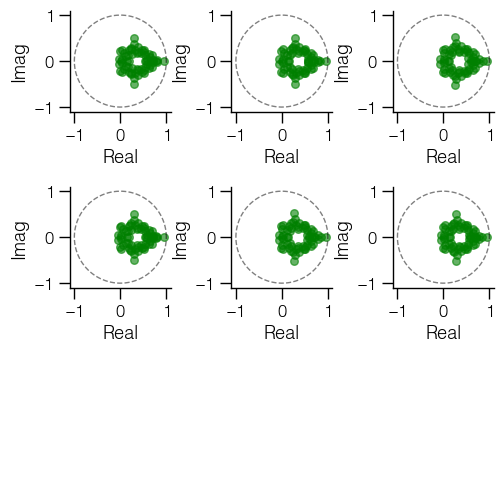

<Figure size 640x480 with 0 Axes>

Session 175: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000175.pkl


Trial 0, patch 3  (global steps 738–866, length 129)  → 129 segments with ≥2 steps


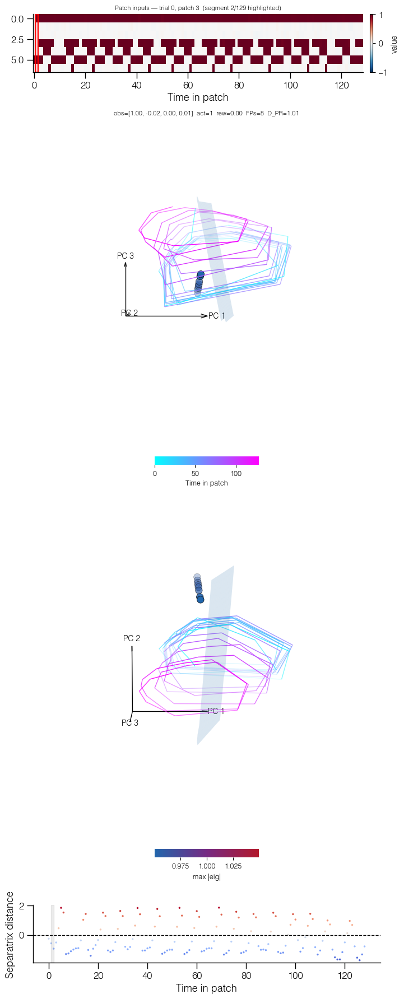

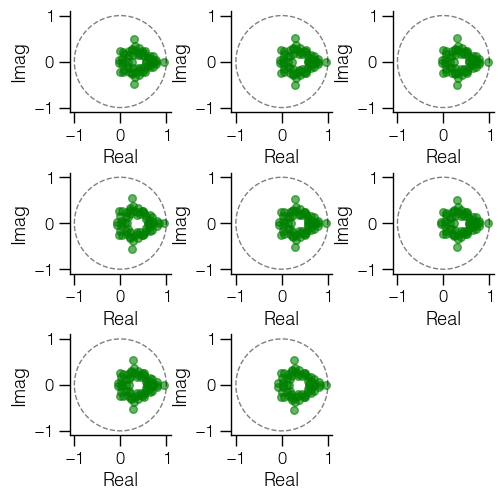

<Figure size 640x480 with 0 Axes>

Session 200: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000200.pkl


Trial 0, patch 3  (global steps 932–1030, length 99)  → 99 segments with ≥2 steps


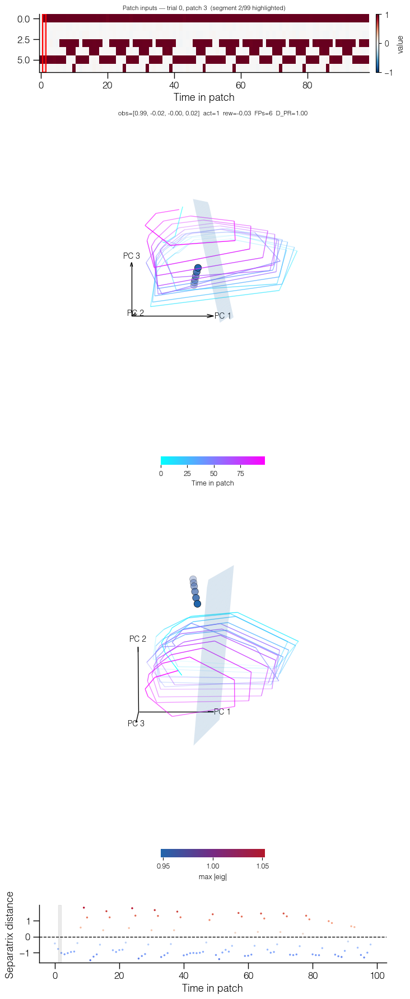

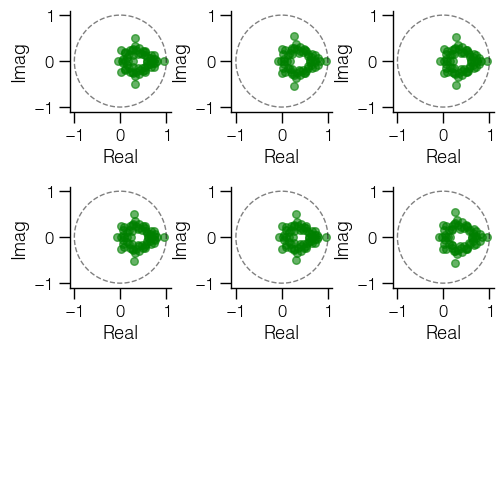

<Figure size 640x480 with 0 Axes>

Session 500: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000500.pkl


Trial 0, patch 3  (global steps 792–961, length 170)  → 170 segments with ≥2 steps


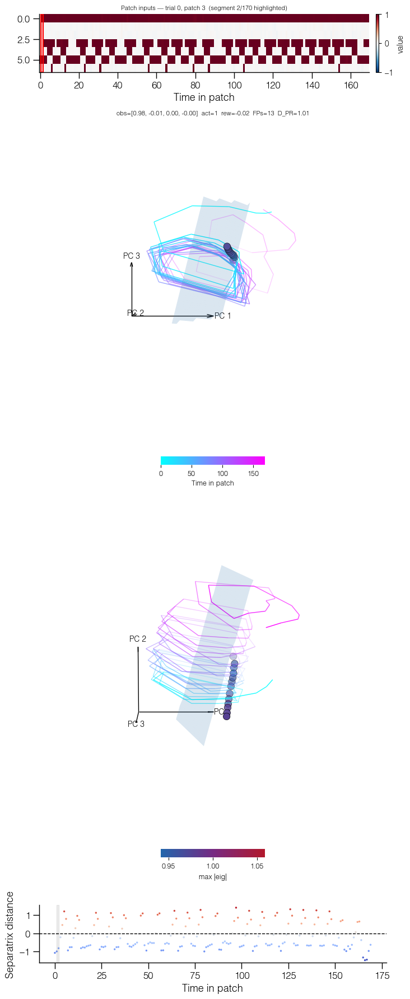

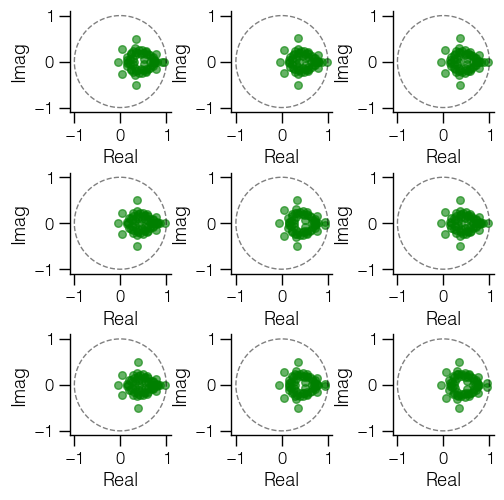

<Figure size 640x480 with 0 Axes>

Session 900: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000900.pkl


Trial 0, patch 3  (global steps 548–656, length 109)  → 109 segments with ≥2 steps


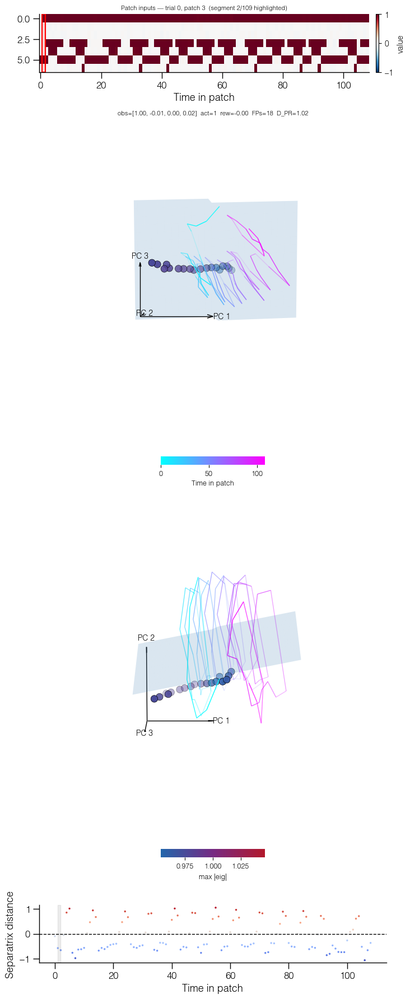

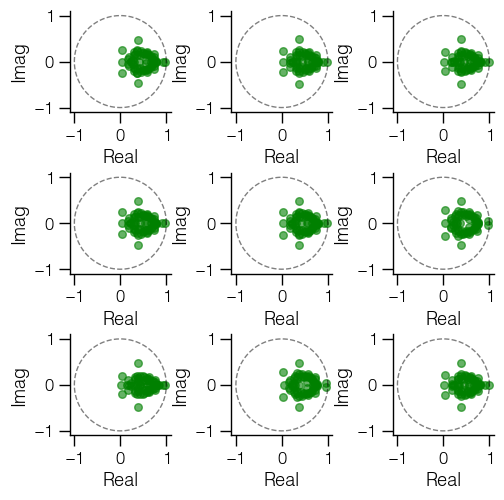

<Figure size 640x480 with 0 Axes>

Session 1900: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_001900.pkl


Trial 0, patch 3  (global steps 808–915, length 108)  → 108 segments with ≥2 steps


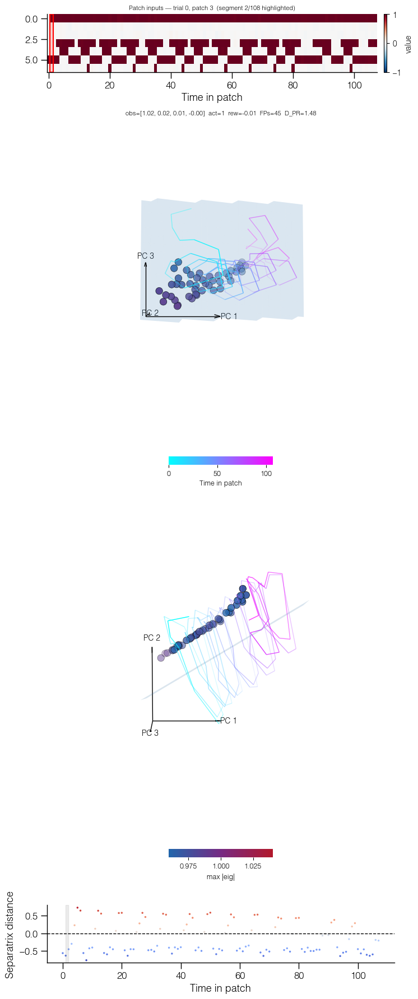

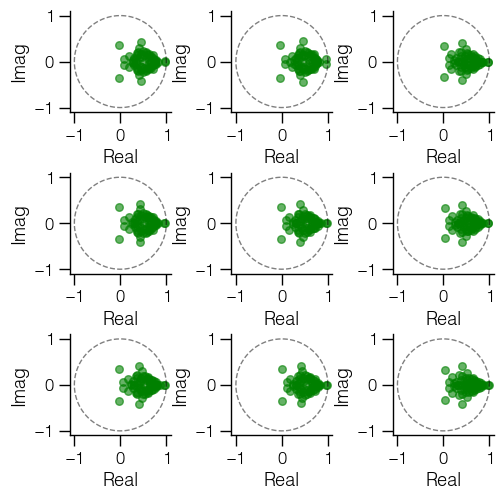

<Figure size 640x480 with 0 Axes>

In [37]:
import re

STRUCT_EVO_RESULTS_DIR = Path('../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed')
STRUCT_EVO_CKPT_DIR = Path('../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_reward_normed')

# Collect all (session_abs, traj_path, ckpt_path) triples
pairs = []
for traj_path in sorted(STRUCT_EVO_RESULTS_DIR.rglob('traj_*.pkl')):
    m = re.search(r'traj_(\d+)\.pkl$', traj_path.name)
    if not m:
        continue
    session_abs = int(m.group(1))
    step_dir = traj_path.parent.name  # e.g. 'step_00'
    ckpt_path = STRUCT_EVO_CKPT_DIR / step_dir / f'checkpoint_{session_abs}'
    if ckpt_path.exists():
        pairs.append((session_abs, traj_path, ckpt_path))

pairs.sort(key=lambda x: x[0])
print(f'Found {len(pairs)} traj/checkpoint pairs')

# Sessions 0, 100, 200, ..., 900
target_sessions = set([0, 25, 50, 75, 100, 125, 150, 175, 200, 500, 900, 1900])
selected = [(s, t, c) for s, t, c in pairs if s in target_sessions]
print(f'Selected {len(selected)} pairs at sessions: {[s for s, _, _ in selected]}')

for session_abs, traj_path, ckpt_path in selected:
    # if session_abs > 0:
    #     continue
    print(f'{"="*60}')
    print(f'Session {session_abs}: {traj_path}')
    print(f'{"="*60}')

    traj_data_raw = load_trajectory_data(str(traj_path))
    traj_data = parse_behavioral_data(traj_data_raw[0])

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])

    restored = checkpoints.restore_checkpoint(ckpt_dir=ckpt_path.resolve(), target=train_state)
    net_params = restored.params

    save_dir = os.path.join(
        '../../../figures',
        'structure_evo_exp_gru_initial_prob_offset',
        f'session_{session_abs:06d}',
    )

    plot_patch_segments_with_fixed_points(
        traj_data, net_params, network, pca,
        trial_idx=0,
        patch_idx=3,
        patch_type=2,
        n_fp_attempts=300,
        fp_tol=1e-3,
        azim=270,
        elev=0,
        azim2=90 + 180,
        elev2=160 + -60,
        includes_actions_and_rewards=True,
        stop_after_unique_inputs=True,
        round_inputs_for_uniqueness=True,
        traj_cmap=sns.color_palette(palette='cool', as_cmap=True),
        save_dir=save_dir,
        plot_current_segment=False,
        target_inputs=[
            [1, 0, 0, 0, 0, 1, 0]
        ],
    )

### Number and stability of fixed points across training

For the same input `[1, 0, 0, 0, 0, 1, 0]`, find the fixed points at each target
session and summarise (a) the number of fixed points vs. session and (b) the
spectrum of each fixed point's largest absolute eigenvalue, with each target
session coloured by a sequential colormap.

In [39]:
import re
from pathlib import Path
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize


def plot_fixed_point_evolution(
    results_dir,
    ckpt_dir,
    network,
    train_state,
    input_vecs,
    input_labels=None,
    target_sessions=None,
    n_fp_attempts=300,
    fp_tol=5e-3,
    fp_uniqueness_threshold=0.1,
    reward_rates_step='step_00',
    perf_threshold=0.068,
    fp_max_steps=60000,
    fp_lr=0.001,
    seed=42,
    cmap='viridis',
    figsize=(4.5, 3),
    marker_size=12,
):
    """Fixed-point structure and performance across training checkpoints.

    For each saved checkpoint (one per `traj_*.pkl` under `results_dir`, matched
    to a checkpoint under `ckpt_dir`) whose session is in `target_sessions`, find
    the fixed points induced by each input in `input_vecs` and produce, per input:
      (a) number of fixed points vs session,
      (b) spectrum of each fixed point's largest |eigenvalue| vs session,
    with axes standardized across inputs and sessions coloured by `cmap`.
    A final performance plot shows the mean reward rate (from the saved
    `_reward_rates/<reward_rates_step>` files) vs session.

    Returns a dict with the collected arrays.
    """
    results_dir = Path(results_dir)
    ckpt_dir = Path(ckpt_dir)
    input_vecs = [jnp.asarray(v) for v in input_vecs]
    if input_labels is None:
        input_labels = [str([int(x) for x in np.array(v)]) for v in input_vecs]
    if target_sessions is None:
        target_sessions = np.arange(0, 2000, 25)
    target_sessions = set(int(s) for s in target_sessions)

    # Collect (session_abs, traj_path, ckpt_path) triples
    pairs = []
    for traj_path in sorted(results_dir.rglob('traj_*.pkl')):
        m = re.search(r'traj_(\d+)\.pkl$', traj_path.name)
        if not m:
            continue
        session_abs = int(m.group(1))
        step_dir = traj_path.parent.name
        ckpt_path = ckpt_dir / step_dir / f'checkpoint_{session_abs}'
        if ckpt_path.exists():
            pairs.append((session_abs, traj_path, ckpt_path))
    pairs.sort(key=lambda x: x[0])

    selected = [(s, t, c) for s, t, c in pairs if s in target_sessions]
    print(f'Selected {len(selected)} pairs at sessions: {[s for s, _, _ in selected]}')

    reward_rates_dir = ckpt_dir / '_reward_rates' / reward_rates_step

    n_inputs = len(input_vecs)
    fp_session_list = []
    fp_perf_list = []                                  # mean reward rate per session (input-independent)
    fp_count_per_input = [[] for _ in range(n_inputs)]      # [input][session] -> n fixed points
    fp_max_eigs_per_input = [[] for _ in range(n_inputs)]   # [input][session] -> array of spectral radii

    for session_abs, traj_path, ckpt_path in selected:
        print(f'Session {session_abs}:')

        traj_data_raw = load_trajectory_data(str(traj_path))
        traj_data = parse_behavioral_data(traj_data_raw[0])

        restored = checkpoints.restore_checkpoint(ckpt_dir=ckpt_path.resolve(), target=train_state)
        net_params = restored.params

        # Seed the fixed-point search from random recorded hidden states
        key = jax.random.PRNGKey(seed)
        idx = jax.random.randint(key, (n_fp_attempts,), 0, traj_data['actor_hidden'].shape[0])
        h_inits = jnp.array(traj_data['actor_hidden'][idx])

        fp_session_list.append(session_abs)
        rr_path = reward_rates_dir / f'{session_abs:06d}'
        if rr_path.exists():
            with open(rr_path, 'rb') as _f:
                rr = np.load(_f)
            fp_perf_list.append(float(np.mean(rr)))
        else:
            fp_perf_list.append(np.nan)

        for i_in, input_vec in enumerate(input_vecs):
            fps, converged, _ = find_fixed_points_batch(
                params=net_params, network=network, input_vec=input_vec,
                h_inits=h_inits, max_steps=fp_max_steps, learning_rate=fp_lr,
                tolerance=fp_tol, verbose=False,
            )
            unique_fps = filter_unique_fixed_points(
                fps, converged, uniqueness_threshold=fp_uniqueness_threshold,
            )
            n_fps = len(unique_fps)
            if n_fps > 0:
                eigenvalues = analyze_stability_batch(unique_fps, input_vec, net_params, network)
                max_eigs = np.array(jnp.max(jnp.abs(eigenvalues), axis=-1))   # spectral radius per FP
            else:
                max_eigs = np.array([])
            fp_count_per_input[i_in].append(n_fps)
            fp_max_eigs_per_input[i_in].append(max_eigs)
            print(f'  input {input_labels[i_in]}: {n_fps} unique fixed points')
        print(f'  reward rate {fp_perf_list[-1]:.4f}')

    if not fp_session_list:
        print('No checkpoints matched the requested sessions.')
        return None

    # Standardized axis limits shared across input sets
    all_counts = [c for lst in fp_count_per_input for c in lst]
    count_ymax = (max(all_counts) if all_counts else 1) + 0.5
    all_eigs = [me for lst in fp_max_eigs_per_input for me in lst if len(me) > 0]
    if all_eigs:
        all_eigs = np.concatenate(all_eigs)
        # include |eig| = 1 in the range so the reference line is always visible
        eig_lo = min(float(all_eigs.min()), 1.0)
        eig_hi = max(float(all_eigs.max()), 1.0)
        pad = 0.05 * (eig_hi - eig_lo) if eig_hi > eig_lo else 0.05
        eig_ylim = (eig_lo - pad, eig_hi + pad)
    else:
        eig_ylim = (0.0, 1.05)
    max_n_fps = max(all_counts) if all_counts else 1

    # Sequential colormap keyed on session
    cmap_obj = plt.get_cmap(cmap) if isinstance(cmap, str) else cmap
    norm = Normalize(vmin=min(fp_session_list), vmax=max(fp_session_list))

    figs = []
    for i_in in range(n_inputs):
        counts = fp_count_per_input[i_in]

        # (a) Number of fixed points vs session
        fig_a, ax_a = plt.subplots(figsize=figsize)
        ax_a.plot(fp_session_list, counts, color='lightgray', lw=1, zorder=1)
        ax_a.scatter(fp_session_list, counts,
                     c=[cmap_obj(norm(s)) for s in fp_session_list], s=marker_size, zorder=2,
                     edgecolors='k', linewidths=0.5)
        ax_a.set_xlabel('Session')
        ax_a.set_ylabel('Number of fixed points')
        ax_a.set_ylim(0, count_ymax)
        ax_a.set_title(f'Fixed points induced by input {input_labels[i_in]}')
        format_plot(ax_a)
        fig_a.tight_layout()
        plt.show()
        figs.append(fig_a)

        # (b) Spectrum of largest |eigenvalue| of the fixed points, per session
        fig_b, ax_b = plt.subplots(figsize=figsize)
        for s, max_eigs in zip(fp_session_list, fp_max_eigs_per_input[i_in]):
            if len(max_eigs) == 0:
                continue
            sorted_eigs = np.sort(max_eigs)[::-1]
            ax_b.plot(np.arange(1, len(sorted_eigs) + 1), sorted_eigs,
                      marker='o', ms=4, lw=1, color=cmap_obj(norm(s)), alpha=0.85)
        ax_b.axhline(1.0, color='red', ls='--', lw=1, alpha=0.5, label='|eig| = 1')
        ax_b.set_xlim(0.5, max_n_fps + 0.5)
        ax_b.set_ylim(*eig_ylim)
        ax_b.set_xlabel('Fixed point (sorted by largest |eig|)')
        ax_b.set_ylabel('Largest |eigenvalue|')
        ax_b.set_title(f'Spectrum of fixed-point spectral radii — input {input_labels[i_in]}')
        ax_b.legend(fontsize=8, frameon=False)
        sm = ScalarMappable(cmap=cmap_obj, norm=norm)
        sm.set_array([])
        cb = fig_b.colorbar(sm, ax=ax_b, label='Session')
        cb.outline.set_visible(False)
        format_plot(ax_b)
        fig_b.tight_layout()
        plt.show()
        figs.append(fig_b)

    # (c) Performance (mean reward rate) vs session
    perf = np.array(fp_perf_list)
    sess = np.array(fp_session_list)
    mask = np.isfinite(perf)
    fig_c, ax_c = plt.subplots(figsize=figsize)
    ax_c.plot(sess[mask], perf[mask], color='lightgray', lw=1, zorder=1)
    ax_c.scatter(sess[mask], perf[mask],
                 c=[cmap_obj(norm(s)) for s in sess[mask]], s=marker_size, zorder=2,
                 edgecolors='k', linewidths=0.5)
    if perf_threshold is not None:
        ax_c.axhline(perf_threshold, color='red', ls='--', lw=1, alpha=0.5)
    ax_c.set_xlabel('Session')
    ax_c.set_ylabel('Mean reward rate')
    ax_c.set_title(f'Performance across training ({reward_rates_step})')
    format_plot(ax_c)
    fig_c.tight_layout()
    plt.show()
    figs.append(fig_c)

    return {
        'sessions': np.array(fp_session_list),
        'counts': fp_count_per_input,
        'max_eigs': fp_max_eigs_per_input,
        'performance': perf,
        'input_labels': input_labels,
        'figs': figs,
    }


Selected 80 pairs at sessions: [0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 525, 550, 575, 600, 625, 650, 675, 700, 725, 750, 775, 800, 825, 850, 875, 900, 925, 950, 975, 1000, 1025, 1050, 1075, 1100, 1125, 1150, 1175, 1200, 1225, 1250, 1275, 1300, 1325, 1350, 1375, 1400, 1425, 1450, 1475, 1500, 1525, 1550, 1575, 1600, 1625, 1650, 1675, 1700, 1725, 1750, 1775, 1800, 1825, 1850, 1875, 1900, 1925, 1950, 1975]
Session 0:


  input [1, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  reward rate 0.0130
Session 25:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  reward rate 0.0559
Session 50:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 8 unique fixed points
  reward rate 0.0608
Session 75:


  input [1, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 7 unique fixed points
  reward rate 0.0629
Session 100:


  input [1, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0649
Session 125:


... (71 outputs left out)

  input [1, 0, 0, 0, 0, 1, 0]: 47 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 10 unique fixed points
  reward rate 0.0674
Session 1925:


  input [1, 0, 0, 0, 0, 1, 0]: 65 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 8 unique fixed points
  reward rate 0.0673
Session 1950:


  input [1, 0, 0, 0, 0, 1, 0]: 46 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  reward rate 0.0670
Session 1975:


  input [1, 0, 0, 0, 0, 1, 0]: 53 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 7 unique fixed points
  reward rate 0.0676


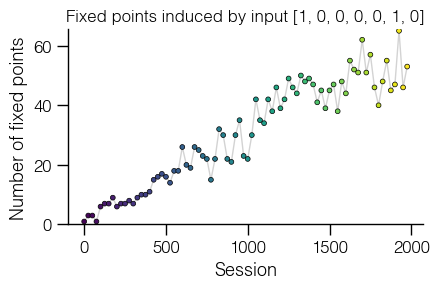

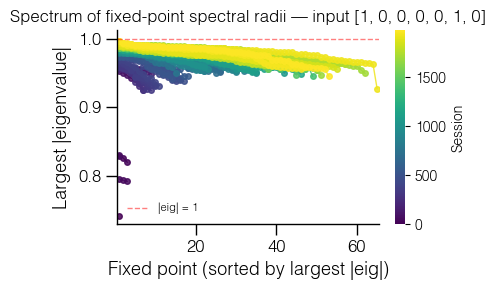

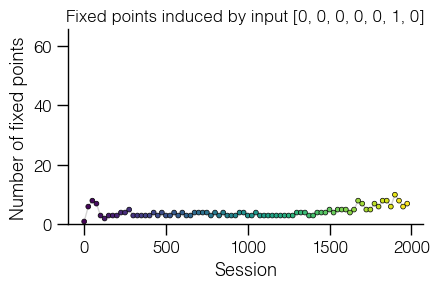

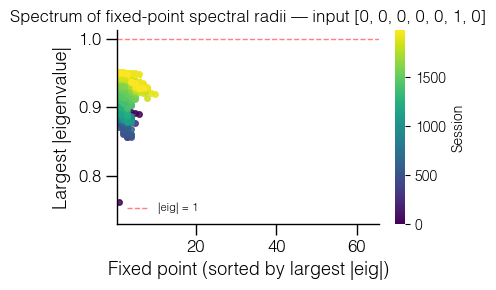

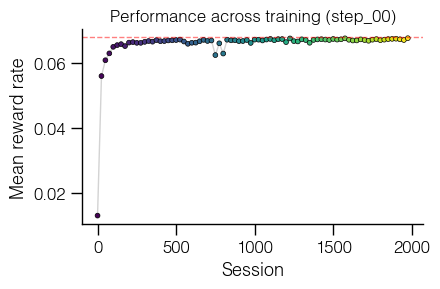

In [40]:
# Reproduce the original analysis for structure_evo_exp_gru_initial_prob_offset
_fp_evo = plot_fixed_point_evolution(
    results_dir=STRUCT_EVO_RESULTS_DIR,
    ckpt_dir=STRUCT_EVO_CKPT_DIR,
    network=network,
    train_state=train_state,
    input_vecs=[
        jnp.array([1., 0., 0., 0., 0., 1., 0.]),   # in patch, no odor
        jnp.array([0., 0., 0., 0., 0., 1., 0.]),   # out of patch
    ],
    target_sessions=np.arange(0, 2000, 25),
    n_fp_attempts=400,
    fp_tol=1e-3,
    fp_uniqueness_threshold=0.1,
    perf_threshold=0.068,
)


Selected 50 pairs at sessions: [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150, 155, 160, 165, 170, 175, 180, 185, 190, 195, 200, 205, 210, 215, 220, 225, 230, 235, 240, 245]
Session 0:


  input [1, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  reward rate 0.0130
Session 5:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0315
Session 10:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  reward rate 0.0457
Session 15:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 9 unique fixed points
  reward rate 0.0507
Session 20:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 7 unique fixed points
  reward rate 0.0540
Session 25:


... (41 outputs left out)

  input [1, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0660
Session 235:


  input [1, 0, 0, 0, 0, 1, 0]: 7 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0657
Session 240:


  input [1, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0618
Session 245:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0638


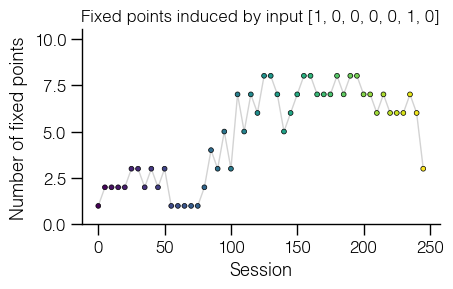

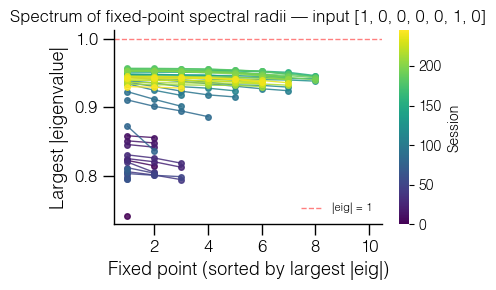

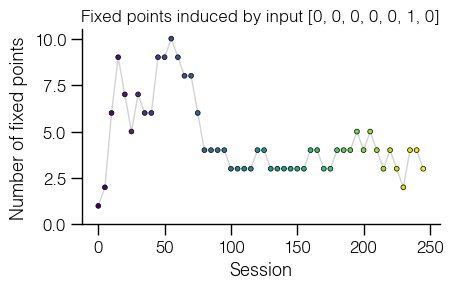

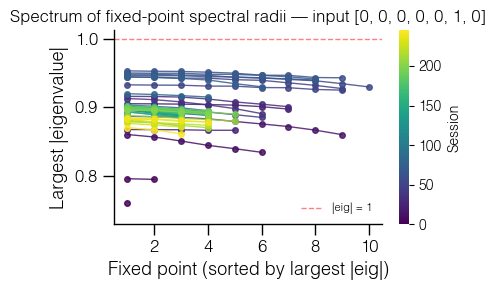

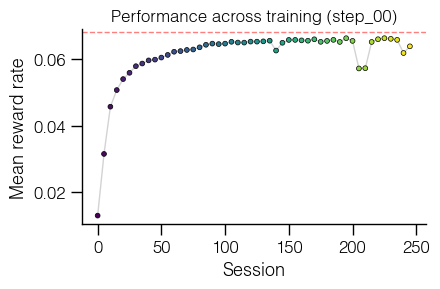

In [42]:
STRUCT_EVO_RESULTS_DIR_FIRST_250 = Path('../../../results/structure_evo_exp_gru_initial_prob_offset_first_250')
STRUCT_EVO_CKPT_DIR_FIRST_250 = Path('../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_first_250')

# Reproduce the original analysis for structure_evo_exp_gru_initial_prob_offset
_fp_evo = plot_fixed_point_evolution(
    results_dir=STRUCT_EVO_RESULTS_DIR_FIRST_250,
    ckpt_dir=STRUCT_EVO_CKPT_DIR_FIRST_250,
    network=network,
    train_state=train_state,
    input_vecs=[
        jnp.array([1., 0., 0., 0., 0., 1., 0.]),   # in patch, no odor
        jnp.array([0., 0., 0., 0., 0., 1., 0.]),   # out of patch
    ],
    target_sessions=np.arange(0, 250, 5),
    n_fp_attempts=400,
    fp_tol=1e-3,
    fp_uniqueness_threshold=0.1,
    perf_threshold=0.068,
)